In [1]:
import configparser
import json
import os
import re

import joblib
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import shap
from venn import venn

In [2]:
os.chdir('../')

In [3]:
data = configparser.ConfigParser(interpolation=configparser.ExtendedInterpolation())
data.read('data.ini')
data = data['DEFAULT']

In [4]:
with open(data['ml'] + 'tools_features_selection.json', 'r') as file:
    features_selections = json.load(file)

features_selections_genes = {}
for key, value in features_selections.items():
    features_selections_genes[key] = value['genes']

# maxmif HN - onlyRAS_onlyNonRAS

In [5]:
onlyRAS = set(features_selections_genes['maxmif HN - onlyRAS'])
onlyNonRAS = set(features_selections_genes['maxmif HN - onlyRAS_onlyNonRAS']) - onlyRAS
len(onlyRAS), len(onlyNonRAS)

(443, 2042)

## mutclust

In [6]:
suffix = 'TCGA_tran&mut_["mutclust - ALL"]'
modelsDir = f'{data['ml___models']}optimized_accuracy/{suffix}'
inputDir = f'{data['ml___input']}{suffix}'
key = 'maxmif HN - onlyRAS_onlyNonRAS'

model_LR_maxmifHN_mutclust = joblib.load(f'{modelsDir}/[\"{key}\"]/logisticRegression.joblib')
model_LRl_maxmifHN_mutclust = joblib.load(f'{modelsDir}/[\"{key}\"]/logisticRegressionLasso.joblib')
model_lSVM_maxmifHN_mutclust = joblib.load(f'{modelsDir}/[\"{key}\"]/linearSVM.joblib')
model_RF_maxmifHN_mutclust = joblib.load(f'{modelsDir}/[\"{key}\"]/randomForest.joblib')

scaler = joblib.load(f'{modelsDir}/[\"{key}\"]/scaler.joblib')

with open(f'{modelsDir}/[\"{key}\"]/features_info.json') as f:
    info_maxmifHN_mutclust = json.load(f)

train_RAS = pd.read_csv(f'{inputDir}/train_RAS.csv', sep=',', comment='#', engine='python')
train_nonRAS = pd.read_csv(f'{inputDir}/train_nonRAS.csv', sep=',', comment='#', engine='python')
test_RAS = pd.read_csv(f'{inputDir}/test_RAS.csv', sep=',', comment='#', engine='python')
test_nonRAS = pd.read_csv(f'{inputDir}/test_nonRAS.csv', sep=',', comment='#', engine='python')

train_maxmifHN_mutclust = scaler.transform(pd.concat([train_RAS, train_nonRAS])[info_maxmifHN_mutclust['valid_features_train']])
test_maxmifHN_mutclust = scaler.transform(pd.concat([test_RAS, test_nonRAS])[info_maxmifHN_mutclust['valid_features_train']])

In [7]:
suffix = 'TCGA_tran&mut_["mutclust - ALL"]'
modelsDir = f'{data['ml___models']}optimized_accuracy/{suffix}'
inputDir = f'{data['ml___input']}{suffix}'
key = 'maxmif HN S - onlyRAS_onlyNonRAS'

model_RF_maxmifHNS_mutclust = joblib.load(f'{modelsDir}/[\"{key}\"]/randomForest.joblib')

scaler = joblib.load(f'{modelsDir}/[\"{key}\"]/scaler.joblib')

with open(f'{modelsDir}/[\"{key}\"]/features_info.json') as f:
    info_maxmifHNS_mutclust = json.load(f)

In [8]:
shapValues = np.mean(shap.LinearExplainer(model_LR_maxmifHN_mutclust, train_maxmifHN_mutclust).shap_values(test_maxmifHN_mutclust), axis=0)
shapValuesMean_LR = pd.DataFrame({'feature': info_maxmifHN_mutclust['valid_features_train'], 'LR shap': shapValues})

shapValues = np.mean(shap.LinearExplainer(model_LRl_maxmifHN_mutclust, train_maxmifHN_mutclust).shap_values(test_maxmifHN_mutclust), axis=0)
shapValuesMean_LRl = pd.DataFrame({'feature': info_maxmifHN_mutclust['valid_features_train'], 'LRl shap': shapValues})

shapValues = np.mean(shap.LinearExplainer(model_lSVM_maxmifHN_mutclust, train_maxmifHN_mutclust).shap_values(test_maxmifHN_mutclust), axis=0)
shapValuesMean_lSVM = pd.DataFrame({'feature': info_maxmifHN_mutclust['valid_features_train'], 'lSVM shap': shapValues})

shapValues = np.mean(np.load('data/feature_importance/TCGA_tran&mut_["mutclust - ALL"]_["maxmifHN S - onlyRAS_onlyNonRAS"]_randomForest_shapValues.npy'), axis=0)
shapValuesMean_RF = pd.DataFrame({'feature': info_maxmifHNS_mutclust['valid_features_train'], 'RF shap': shapValues})

importance_maxmifHN_mutclust_LR_LRl = pd.merge(shapValuesMean_LR, shapValuesMean_LRl, on='feature', how='inner')
importance_maxmifHN_mutclust_LR_LRl_lSVM = pd.merge(importance_maxmifHN_mutclust_LR_LRl, shapValuesMean_lSVM, on='feature', how='inner')
importance_maxmifHN_mutclust = pd.merge(importance_maxmifHN_mutclust_LR_LRl_lSVM, shapValuesMean_RF, on='feature', how='inner')
importance_maxmifHN_mutclust['gene'] = importance_maxmifHN_mutclust['feature'].str.split('_').str[0]
importance_maxmifHN_mutclust['from'] = importance_maxmifHN_mutclust['gene'].apply(lambda x: 'RAS' if x in onlyRAS else ('nonRAS' if x in onlyNonRAS else '-'))

cols = list(importance_maxmifHN_mutclust.columns)
cols.insert(1, cols.pop(cols.index('gene')))
cols.insert(2, cols.pop(cols.index('from')))
importance_maxmifHN_mutclust = importance_maxmifHN_mutclust[cols]

numerical_cols = importance_maxmifHN_mutclust.select_dtypes(include=['number']).columns
importance_maxmifHN_mutclust[numerical_cols] = importance_maxmifHN_mutclust[numerical_cols].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
importance_maxmifHN_mutclust['sum'] = importance_maxmifHN_mutclust[numerical_cols].sum(axis=1)
importance_maxmifHN_mutclust[['sum']] = importance_maxmifHN_mutclust[['sum']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
importance_maxmifHN_mutclust = importance_maxmifHN_mutclust.sort_values('sum', ascending=False)

In [9]:
importance_maxmifHN_mutclust

,feature,gene,from,LR shap,LRl shap,lSVM shap,RF shap,sum
785,IGSF10_tran,IGSF10,nonRAS,0.671551,0.732286,0.713882,-0.007158,0.631780
3490,NFKBIZ_noCluster,NFKBIZ,nonRAS,0.662564,0.672779,0.676377,0.000000,0.602193
3102,IL6R_noCluster,IL6R,nonRAS,0.530015,0.741162,0.615311,0.016167,0.569545
1573,SEMA7A_tran,SEMA7A,nonRAS,0.477969,0.876171,0.462152,0.019939,0.549662
4377,TFRC_noCluster,TFRC,nonRAS,0.721728,0.565662,0.519709,0.000006,0.540943
...,...,...,...,...,...,...,...,...
322,COA1_tran,COA1,RAS,-0.614820,-0.623516,-0.555602,-0.094492,-0.565287
212,CAPN12_tran,CAPN12,nonRAS,-0.842614,-0.501465,-0.805689,-0.008821,-0.646157
221,CBX3_tran,CBX3,RAS,-0.833398,-0.823126,-0.774451,-0.001782,-0.728227
3640,PCDHB2_noCluster,PCDHB2,nonRAS,-1.000000,-0.849450,-1.000000,0.000660,-0.852763


In [10]:
plot_LR_maxmifHN_mutclust = pd.DataFrame(
    [(i, len(importance_maxmifHN_mutclust.loc[importance_maxmifHN_mutclust['LR shap'] > i, 'feature'])) for i in np.arange(importance_maxmifHN_mutclust['LR shap'].max(), importance_maxmifHN_mutclust['LR shap'].min(), -0.001)],
    columns=['shap', 'numFeatures']
)

plot_lSVM_maxmifHN_mutclust = pd.DataFrame(
    [(i, len(importance_maxmifHN_mutclust.loc[importance_maxmifHN_mutclust['lSVM shap'] > i, 'feature'])) for i in np.arange(importance_maxmifHN_mutclust['lSVM shap'].max(), importance_maxmifHN_mutclust['lSVM shap'].min(), -0.001)],
    columns=['shap', 'numFeatures']
)

plot_LRl_maxmifHN_mutclust = pd.DataFrame(
    [(i, len(importance_maxmifHN_mutclust.loc[importance_maxmifHN_mutclust['LRl shap'] > i, 'feature'])) for i in np.arange(importance_maxmifHN_mutclust['LRl shap'].max(), importance_maxmifHN_mutclust['LRl shap'].min(), -0.001)],
    columns=['shap', 'numFeatures']
)

plot_RF_maxmifHN_mutclust = pd.DataFrame(
    [(i, len(importance_maxmifHN_mutclust.loc[importance_maxmifHN_mutclust['RF shap'] > i, 'feature'])) for i in np.arange(importance_maxmifHN_mutclust['RF shap'].max(), importance_maxmifHN_mutclust['RF shap'].min(), -0.001)],
    columns=['shap', 'numFeatures']
)

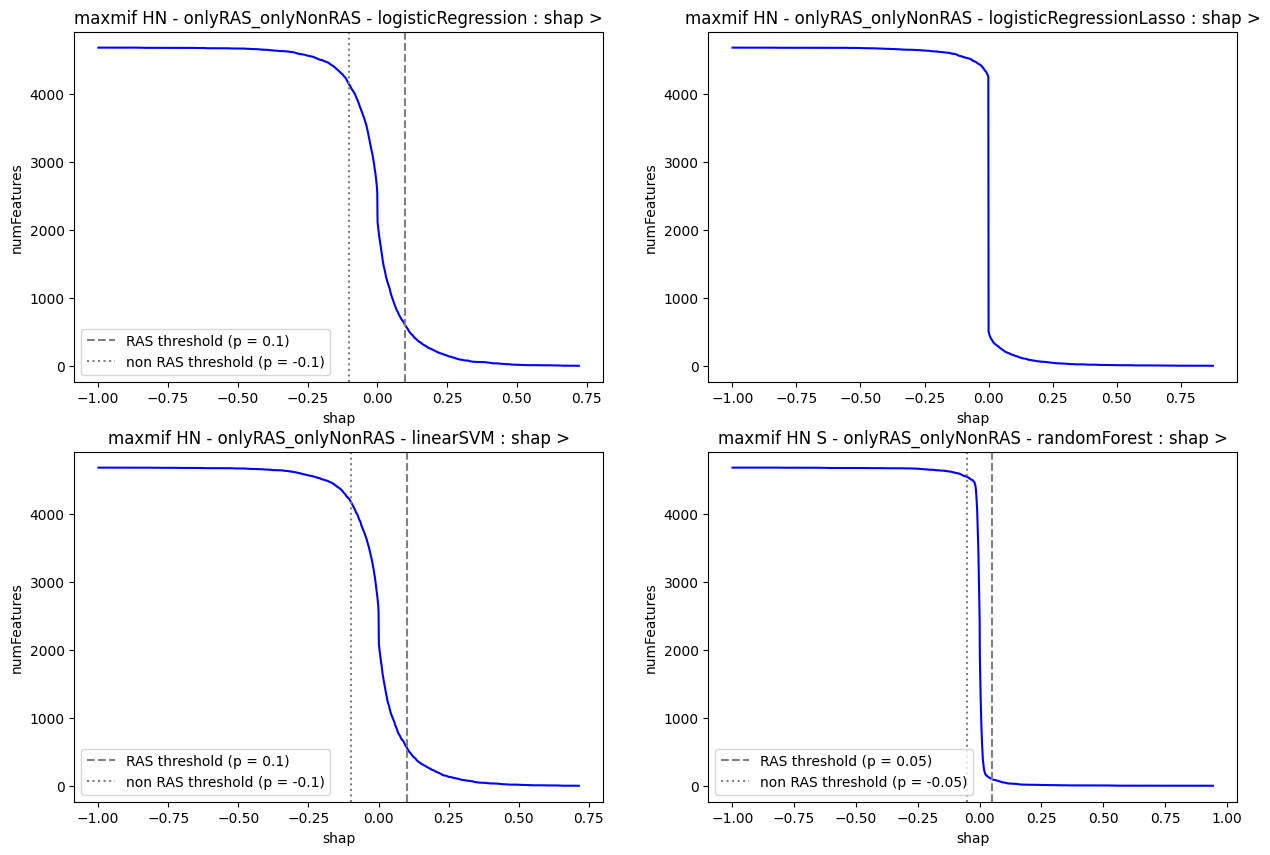

In [11]:
# plot both in different plots
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
ax = ax.flatten()

ax[0].plot(plot_LR_maxmifHN_mutclust['shap'], plot_LR_maxmifHN_mutclust['numFeatures'], color='blue')
ax[0].axvline(x=0.1, color='grey', linestyle='--', label='RAS threshold (p = 0.1)')
ax[0].axvline(x=-0.1, color='grey', linestyle=':', label='non RAS threshold (p = -0.1)')
ax[0].set_xlabel('shap')
ax[0].set_ylabel('numFeatures')
ax[0].set_title('maxmif HN - onlyRAS_onlyNonRAS - logisticRegression : shap >')
ax[0].legend()

ax[1].plot(plot_LRl_maxmifHN_mutclust['shap'], plot_LRl_maxmifHN_mutclust['numFeatures'], color='blue')
ax[1].set_xlabel('shap')
ax[1].set_ylabel('numFeatures')
ax[1].set_title('maxmif HN - onlyRAS_onlyNonRAS - logisticRegressionLasso : shap >')

ax[2].plot(plot_lSVM_maxmifHN_mutclust['shap'], plot_lSVM_maxmifHN_mutclust['numFeatures'], color='blue')
ax[2].axvline(x=0.1, color='grey', linestyle='--', label='RAS threshold (p = 0.1)')
ax[2].axvline(x=-0.1, color='grey', linestyle=':', label='non RAS threshold (p = -0.1)')
ax[2].set_xlabel('shap')
ax[2].set_ylabel('numFeatures')
ax[2].set_title('maxmif HN - onlyRAS_onlyNonRAS - linearSVM : shap >')
ax[2].legend()

ax[3].plot(plot_RF_maxmifHN_mutclust['shap'], plot_RF_maxmifHN_mutclust['numFeatures'], color='blue')
ax[3].axvline(x=0.05, color='grey', linestyle='--', label='RAS threshold (p = 0.05)')
ax[3].axvline(x=-0.05, color='grey', linestyle=':', label='non RAS threshold (p = -0.05)')
ax[3].set_xlabel('shap')
ax[3].set_ylabel('numFeatures')
ax[3].set_title('maxmif HN S - onlyRAS_onlyNonRAS - randomForest : shap >')
ax[3].legend()

plt.savefig('data/plots/fia/s_mutclust_thresholds.png')
plt.show()

#### significant features

In [12]:
RAS_significantFeatures_LR_maxmifHN_mutclust = set(importance_maxmifHN_mutclust[importance_maxmifHN_mutclust['LR shap'] > 0.1]['feature'])
RAS_significantFeatures_lSVM_maxmifHN_mutclust = set(importance_maxmifHN_mutclust[importance_maxmifHN_mutclust['lSVM shap'] > 0.1]['feature'])
RAS_significantFeatures_LRl_maxmifHN_mutclust = set(importance_maxmifHN_mutclust[importance_maxmifHN_mutclust['LRl shap'] > 0]['feature'])
RAS_significantFeatures_RF_maxmifHN_mutclust = set(importance_maxmifHN_mutclust[importance_maxmifHN_mutclust['RF shap'] > 0.05]['feature'])

len(RAS_significantFeatures_LR_maxmifHN_mutclust), len(RAS_significantFeatures_lSVM_maxmifHN_mutclust), len(RAS_significantFeatures_LRl_maxmifHN_mutclust), len(RAS_significantFeatures_RF_maxmifHN_mutclust)

(600, 563, 534, 101)

In [13]:
print("LR & lSVM:\t\t", len(RAS_significantFeatures_LR_maxmifHN_mutclust &RAS_significantFeatures_lSVM_maxmifHN_mutclust))
print("LR & LRl:\t\t", len(RAS_significantFeatures_LR_maxmifHN_mutclust &RAS_significantFeatures_LRl_maxmifHN_mutclust))
print("LR & RF:\t\t", len(RAS_significantFeatures_LR_maxmifHN_mutclust &RAS_significantFeatures_RF_maxmifHN_mutclust))
print("lSVM & LRl:\t\t", len(RAS_significantFeatures_lSVM_maxmifHN_mutclust &RAS_significantFeatures_LRl_maxmifHN_mutclust))
print("lSVM & RF:\t\t", len(RAS_significantFeatures_lSVM_maxmifHN_mutclust &RAS_significantFeatures_RF_maxmifHN_mutclust))
print("LRl & RF:\t\t", len(RAS_significantFeatures_LRl_maxmifHN_mutclust &RAS_significantFeatures_RF_maxmifHN_mutclust))

print("LR & lSVM & LRl:\t", len(RAS_significantFeatures_LR_maxmifHN_mutclust &RAS_significantFeatures_lSVM_maxmifHN_mutclust &RAS_significantFeatures_LRl_maxmifHN_mutclust))
print("LR & lSVM & RF:\t\t", len(RAS_significantFeatures_LR_maxmifHN_mutclust &RAS_significantFeatures_lSVM_maxmifHN_mutclust &RAS_significantFeatures_RF_maxmifHN_mutclust))
print("LR & LRl & RF:\t\t", len(RAS_significantFeatures_LR_maxmifHN_mutclust &RAS_significantFeatures_LRl_maxmifHN_mutclust &RAS_significantFeatures_RF_maxmifHN_mutclust))
print("lSVM & LRl & RF:\t", len(RAS_significantFeatures_lSVM_maxmifHN_mutclust &RAS_significantFeatures_LRl_maxmifHN_mutclust &RAS_significantFeatures_RF_maxmifHN_mutclust))

print("LR & lSVM & LRl & RF:\t", len(RAS_significantFeatures_LR_maxmifHN_mutclust &RAS_significantFeatures_lSVM_maxmifHN_mutclust &RAS_significantFeatures_LRl_maxmifHN_mutclust & RAS_significantFeatures_RF_maxmifHN_mutclust))

LR & lSVM:		 531
LR & LRl:		 318
LR & RF:		 17
lSVM & LRl:		 308
lSVM & RF:		 17
LRl & RF:		 15
LR & lSVM & LRl:	 304
LR & lSVM & RF:		 17
LR & LRl & RF:		 12
lSVM & LRl & RF:	 12
LR & lSVM & LRl & RF:	 12


In [14]:
nonRAS_significantFeatures_LR_maxmifHN_mutclust = set(importance_maxmifHN_mutclust[importance_maxmifHN_mutclust['LR shap'] < -0.1]['feature'])
nonRAS_significantFeatures_lSVM_maxmifHN_mutclust = set(importance_maxmifHN_mutclust[importance_maxmifHN_mutclust['lSVM shap'] < -0.1]['feature'])
nonRAS_significantFeatures_LRl_maxmifHN_mutclust = set(importance_maxmifHN_mutclust[importance_maxmifHN_mutclust['LRl shap'] < 0]['feature'])
nonRAS_significantFeatures_RF_maxmifHN_mutclust = set(importance_maxmifHN_mutclust[importance_maxmifHN_mutclust['RF shap'] < -0.05]['feature'])

In [15]:
print("LR & lSVM:\t\t", len(nonRAS_significantFeatures_LR_maxmifHN_mutclust &nonRAS_significantFeatures_lSVM_maxmifHN_mutclust))
print("LR & LRl:\t\t", len(nonRAS_significantFeatures_LR_maxmifHN_mutclust &nonRAS_significantFeatures_LRl_maxmifHN_mutclust))
print("LR & RF:\t\t", len(nonRAS_significantFeatures_LR_maxmifHN_mutclust &nonRAS_significantFeatures_RF_maxmifHN_mutclust))
print("lSVM & LRl:\t\t", len(nonRAS_significantFeatures_lSVM_maxmifHN_mutclust &nonRAS_significantFeatures_LRl_maxmifHN_mutclust))
print("lSVM & RF:\t\t", len(nonRAS_significantFeatures_lSVM_maxmifHN_mutclust &nonRAS_significantFeatures_RF_maxmifHN_mutclust))
print("LRl & RF:\t\t", len(nonRAS_significantFeatures_LRl_maxmifHN_mutclust &nonRAS_significantFeatures_RF_maxmifHN_mutclust))

print("LR & lSVM & LRl:\t", len(nonRAS_significantFeatures_LR_maxmifHN_mutclust &nonRAS_significantFeatures_lSVM_maxmifHN_mutclust &nonRAS_significantFeatures_LRl_maxmifHN_mutclust))
print("LR & lSVM & RF:\t\t", len(nonRAS_significantFeatures_LR_maxmifHN_mutclust &nonRAS_significantFeatures_lSVM_maxmifHN_mutclust &nonRAS_significantFeatures_RF_maxmifHN_mutclust))
print("LR & LRl & RF:\t\t", len(nonRAS_significantFeatures_LR_maxmifHN_mutclust &nonRAS_significantFeatures_LRl_maxmifHN_mutclust &nonRAS_significantFeatures_RF_maxmifHN_mutclust))
print("lSVM & LRl & RF:\t", len(nonRAS_significantFeatures_lSVM_maxmifHN_mutclust &nonRAS_significantFeatures_LRl_maxmifHN_mutclust &nonRAS_significantFeatures_RF_maxmifHN_mutclust))

print("LR & lSVM & LRl & RF:\t", len(nonRAS_significantFeatures_LR_maxmifHN_mutclust &nonRAS_significantFeatures_lSVM_maxmifHN_mutclust &nonRAS_significantFeatures_LRl_maxmifHN_mutclust &nonRAS_significantFeatures_RF_maxmifHN_mutclust))

LR & lSVM:		 478
LR & LRl:		 257
LR & RF:		 35
lSVM & LRl:		 250
lSVM & RF:		 32
LRl & RF:		 27
LR & lSVM & LRl:	 248
LR & lSVM & RF:		 32
LR & LRl & RF:		 19
lSVM & LRl & RF:	 19
LR & lSVM & LRl & RF:	 19


#### RAS-significant transcriptomic features

In [16]:
RAS_significantTranscriptomic_LR_maxmifHN_mutclust = set([
    f for f in RAS_significantFeatures_LR_maxmifHN_mutclust 
    if not ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
RAS_significantTranscriptomic_lSVM_maxmifHN_mutclust = set([
    f for f in RAS_significantFeatures_lSVM_maxmifHN_mutclust 
    if not ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
RAS_significantTranscriptomic_LRl_maxmifHN_mutclust = set([
    f for f in RAS_significantFeatures_LRl_maxmifHN_mutclust 
    if not ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
RAS_significantTranscriptomic_RF_maxmifHN_mutclust = set([
    f for f in RAS_significantFeatures_RF_maxmifHN_mutclust 
    if not ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
len(RAS_significantTranscriptomic_LR_maxmifHN_mutclust), len(RAS_significantTranscriptomic_lSVM_maxmifHN_mutclust), len(RAS_significantTranscriptomic_LRl_maxmifHN_mutclust), len(RAS_significantTranscriptomic_RF_maxmifHN_mutclust)

(307, 286, 237, 101)

In [17]:
print("LR & lSVM:\t\t", len(RAS_significantTranscriptomic_LR_maxmifHN_mutclust &RAS_significantTranscriptomic_lSVM_maxmifHN_mutclust))
print("LR & LRl:\t\t", len(RAS_significantTranscriptomic_LR_maxmifHN_mutclust &RAS_significantTranscriptomic_LRl_maxmifHN_mutclust))
print("LR & pSVM:\t\t", len(RAS_significantTranscriptomic_LR_maxmifHN_mutclust &RAS_significantTranscriptomic_RF_maxmifHN_mutclust))
print("lSVM & LRl:\t\t", len(RAS_significantTranscriptomic_lSVM_maxmifHN_mutclust &RAS_significantTranscriptomic_LRl_maxmifHN_mutclust))
print("lSVM & pSVM:\t\t", len(RAS_significantTranscriptomic_lSVM_maxmifHN_mutclust &RAS_significantTranscriptomic_RF_maxmifHN_mutclust))
print("LRl & pSVM:\t\t", len(RAS_significantTranscriptomic_LRl_maxmifHN_mutclust &RAS_significantTranscriptomic_RF_maxmifHN_mutclust))

print("LR & lSVM & LRl:\t", len(RAS_significantTranscriptomic_LR_maxmifHN_mutclust &RAS_significantTranscriptomic_lSVM_maxmifHN_mutclust &RAS_significantTranscriptomic_LRl_maxmifHN_mutclust))
print("LR & lSVM & pSVM:\t", len(RAS_significantTranscriptomic_LR_maxmifHN_mutclust &RAS_significantTranscriptomic_lSVM_maxmifHN_mutclust &RAS_significantTranscriptomic_RF_maxmifHN_mutclust))
print("LR & LRl & pSVM:\t", len(RAS_significantTranscriptomic_LR_maxmifHN_mutclust &RAS_significantTranscriptomic_LRl_maxmifHN_mutclust &RAS_significantTranscriptomic_RF_maxmifHN_mutclust))
print("lSVM & LRl & pSVM:\t", len(RAS_significantTranscriptomic_lSVM_maxmifHN_mutclust &RAS_significantTranscriptomic_LRl_maxmifHN_mutclust &RAS_significantTranscriptomic_RF_maxmifHN_mutclust))

print("LR & lSVM & LRl & pSVM:\t", len(RAS_significantTranscriptomic_LR_maxmifHN_mutclust &RAS_significantTranscriptomic_lSVM_maxmifHN_mutclust &RAS_significantTranscriptomic_LRl_maxmifHN_mutclust &RAS_significantTranscriptomic_RF_maxmifHN_mutclust))

LR & lSVM:		 272
LR & LRl:		 152
LR & pSVM:		 17
lSVM & LRl:		 145
lSVM & pSVM:		 17
LRl & pSVM:		 15
LR & lSVM & LRl:	 143
LR & lSVM & pSVM:	 17
LR & LRl & pSVM:	 12
lSVM & LRl & pSVM:	 12
LR & lSVM & LRl & pSVM:	 12


In [18]:
importance_maxmifHN_mutclust[importance_maxmifHN_mutclust['feature'].isin(RAS_significantTranscriptomic_LR_maxmifHN_mutclust & RAS_significantTranscriptomic_lSVM_maxmifHN_mutclust & RAS_significantTranscriptomic_LRl_maxmifHN_mutclust & RAS_significantTranscriptomic_RF_maxmifHN_mutclust)]

,feature,gene,from,LR shap,LRl shap,lSVM shap,RF shap,sum
1685,SPRED1_tran,SPRED1,nonRAS,0.447557,0.230171,0.433739,0.283810,0.417665
125,ARRB2_tran,ARRB2,nonRAS,0.405031,0.241639,0.346614,0.362092,0.405721
33,ADAM19_tran,ADAM19,nonRAS,0.454746,0.105267,0.341295,0.148694,0.314310
466,EEF2K_tran,EEF2K,nonRAS,0.127467,0.032395,0.108656,0.646196,0.273812
1589,SGSM2_tran,SGSM2,nonRAS,0.394152,0.001440,0.343426,0.156347,0.268021
244,CD40_tran,CD40,nonRAS,0.298690,0.204116,0.293461,0.076488,0.261253
515,ERAL1_tran,ERAL1,RAS,0.247513,0.071355,0.240423,0.246914,0.241331
1716,STK39_tran,STK39,RAS,0.274531,0.077661,0.263720,0.065096,0.203855
1273,PLEKHH3_tran,PLEKHH3,nonRAS,0.207835,0.111455,0.195727,0.054070,0.170352
1869,TTLL9_tran,TTLL9,nonRAS,0.178716,0.065644,0.186387,0.115711,0.163578


#### RAS-significant mutational features

In [19]:
RAS_significantMutations_LR_maxmifHN_mutclust  = set([
    f for f in RAS_significantFeatures_LR_maxmifHN_mutclust 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
RAS_significantMutations_lSVM_maxmifHN_mutclust  = set([
    f for f in RAS_significantFeatures_lSVM_maxmifHN_mutclust 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
RAS_significantMutations_LRl_maxmifHN_mutclust  = set([
    f for f in RAS_significantFeatures_LRl_maxmifHN_mutclust 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
RAS_significantMutations_RF_maxmifHN_mutclust  = set([
    f for f in RAS_significantFeatures_RF_maxmifHN_mutclust 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
len(RAS_significantMutations_LR_maxmifHN_mutclust), len(RAS_significantMutations_lSVM_maxmifHN_mutclust), len(RAS_significantMutations_LRl_maxmifHN_mutclust), len(RAS_significantMutations_RF_maxmifHN_mutclust)

(293, 277, 297, 0)

In [20]:
print("LR & lSVM:\t\t", len(RAS_significantMutations_LR_maxmifHN_mutclust &RAS_significantMutations_lSVM_maxmifHN_mutclust))
print("LR & LRl:\t\t", len(RAS_significantMutations_LR_maxmifHN_mutclust &RAS_significantMutations_LRl_maxmifHN_mutclust))
print("LR & pSVM:\t\t", len(RAS_significantMutations_LR_maxmifHN_mutclust &RAS_significantMutations_RF_maxmifHN_mutclust))
print("lSVM & LRl:\t\t", len(RAS_significantMutations_lSVM_maxmifHN_mutclust &RAS_significantMutations_LRl_maxmifHN_mutclust))
print("lSVM & pSVM:\t\t", len(RAS_significantMutations_lSVM_maxmifHN_mutclust &RAS_significantMutations_RF_maxmifHN_mutclust))
print("LRl & pSVM:\t\t", len(RAS_significantMutations_LRl_maxmifHN_mutclust &RAS_significantMutations_RF_maxmifHN_mutclust))

print("LR & lSVM & LRl:\t", len(RAS_significantMutations_LR_maxmifHN_mutclust &RAS_significantMutations_lSVM_maxmifHN_mutclust &RAS_significantMutations_LRl_maxmifHN_mutclust))
print("LR & lSVM & pSVM:\t", len(RAS_significantMutations_LR_maxmifHN_mutclust &RAS_significantMutations_lSVM_maxmifHN_mutclust &RAS_significantMutations_RF_maxmifHN_mutclust))
print("LR & LRl & pSVM:\t", len(RAS_significantMutations_LR_maxmifHN_mutclust &RAS_significantMutations_LRl_maxmifHN_mutclust &RAS_significantMutations_RF_maxmifHN_mutclust))
print("lSVM & LRl & pSVM:\t", len(RAS_significantMutations_lSVM_maxmifHN_mutclust &RAS_significantMutations_LRl_maxmifHN_mutclust &RAS_significantMutations_RF_maxmifHN_mutclust))

print("LR & lSVM & LRl & pSVM:\t", len(RAS_significantMutations_LR_maxmifHN_mutclust &RAS_significantMutations_lSVM_maxmifHN_mutclust &RAS_significantMutations_LRl_maxmifHN_mutclust &RAS_significantMutations_RF_maxmifHN_mutclust))

LR & lSVM:		 259
LR & LRl:		 166
LR & pSVM:		 0
lSVM & LRl:		 163
lSVM & pSVM:		 0
LRl & pSVM:		 0
LR & lSVM & LRl:	 161
LR & lSVM & pSVM:	 0
LR & LRl & pSVM:	 0
lSVM & LRl & pSVM:	 0
LR & lSVM & LRl & pSVM:	 0


In [21]:
importance_maxmifHN_mutclust[importance_maxmifHN_mutclust['feature'].isin(RAS_significantMutations_LR_maxmifHN_mutclust & RAS_significantMutations_lSVM_maxmifHN_mutclust & RAS_significantMutations_LRl_maxmifHN_mutclust & RAS_significantMutations_RF_maxmifHN_mutclust)]

,feature,gene,from,LR shap,LRl shap,lSVM shap,RF shap,sum


#### comparison with maxmif significance in RAS/nonRAS

In [22]:
RAS_significantMutGenes_LR_maxmifHN_mutclust = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in RAS_significantMutations_LR_maxmifHN_mutclust
])
RAS_significantMutGenes_lSVM_maxmifHN_mutclust = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in RAS_significantMutations_lSVM_maxmifHN_mutclust
])
RAS_significantMutGenes_LRl_maxmifHN_mutclust = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in RAS_significantMutations_LRl_maxmifHN_mutclust
])
RAS_significantMutGenes_RF_maxmifHN_mutclust = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in RAS_significantMutations_RF_maxmifHN_mutclust
])
len(RAS_significantMutGenes_LR_maxmifHN_mutclust), len(RAS_significantMutGenes_lSVM_maxmifHN_mutclust), len(RAS_significantMutGenes_LRl_maxmifHN_mutclust), len(RAS_significantMutGenes_RF_maxmifHN_mutclust)

(292, 276, 295, 0)

In [23]:
print("LR & lSVM:\t\t", len(RAS_significantMutGenes_LR_maxmifHN_mutclust &RAS_significantMutGenes_lSVM_maxmifHN_mutclust))
print("LR & LRl:\t\t", len(RAS_significantMutGenes_LR_maxmifHN_mutclust &RAS_significantMutGenes_LRl_maxmifHN_mutclust))
print("LR & pSVM:\t\t", len(RAS_significantMutGenes_LR_maxmifHN_mutclust &RAS_significantMutGenes_RF_maxmifHN_mutclust))
print("lSVM & LRl:\t\t", len(RAS_significantMutGenes_lSVM_maxmifHN_mutclust &RAS_significantMutGenes_LRl_maxmifHN_mutclust))
print("lSVM & pSVM:\t\t", len(RAS_significantMutGenes_lSVM_maxmifHN_mutclust &RAS_significantMutGenes_RF_maxmifHN_mutclust))
print("LRl & pSVM:\t\t", len(RAS_significantMutGenes_LRl_maxmifHN_mutclust &RAS_significantMutGenes_RF_maxmifHN_mutclust))

print("LR & lSVM & LRl:\t", len(RAS_significantMutGenes_LR_maxmifHN_mutclust &RAS_significantMutGenes_lSVM_maxmifHN_mutclust &RAS_significantMutGenes_LRl_maxmifHN_mutclust))
print("LR & lSVM & pSVM:\t", len(RAS_significantMutGenes_LR_maxmifHN_mutclust &RAS_significantMutGenes_lSVM_maxmifHN_mutclust &RAS_significantMutGenes_RF_maxmifHN_mutclust))
print("LR & LRl & pSVM:\t", len(RAS_significantMutGenes_LR_maxmifHN_mutclust &RAS_significantMutGenes_LRl_maxmifHN_mutclust &RAS_significantMutGenes_RF_maxmifHN_mutclust))
print("lSVM & LRl & pSVM:\t", len(RAS_significantMutGenes_lSVM_maxmifHN_mutclust &RAS_significantMutGenes_LRl_maxmifHN_mutclust &RAS_significantMutGenes_RF_maxmifHN_mutclust))

print("LR & lSVM & LRl & pSVM:\t", len(RAS_significantMutGenes_LR_maxmifHN_mutclust &RAS_significantMutGenes_lSVM_maxmifHN_mutclust &RAS_significantMutGenes_LRl_maxmifHN_mutclust &RAS_significantMutGenes_RF_maxmifHN_mutclust))

LR & lSVM:		 258
LR & LRl:		 165
LR & pSVM:		 0
lSVM & LRl:		 162
lSVM & pSVM:		 0
LRl & pSVM:		 0
LR & lSVM & LRl:	 160
LR & lSVM & pSVM:	 0
LR & LRl & pSVM:	 0
lSVM & LRl & pSVM:	 0
LR & lSVM & LRl & pSVM:	 0


In [24]:
nonRAS_significantMutations_LR_maxmifHN_mutclust  = set([
    f for f in nonRAS_significantFeatures_LR_maxmifHN_mutclust 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
nonRAS_significantMutations_lSVM_maxmifHN_mutclust  = set([
    f for f in nonRAS_significantFeatures_lSVM_maxmifHN_mutclust 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
nonRAS_significantMutations_LRl_maxmifHN_mutclust  = set([
    f for f in nonRAS_significantFeatures_LRl_maxmifHN_mutclust 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
nonRAS_significantMutations_RF_maxmifHN_mutclust  = set([
    f for f in nonRAS_significantFeatures_RF_maxmifHN_mutclust 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])

nonRAS_significantMutGenes_LR_maxmifHN_mutclust = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in nonRAS_significantMutations_LR_maxmifHN_mutclust
])
nonRAS_significantMutGenes_lSVM_maxmifHN_mutclust = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in nonRAS_significantMutations_lSVM_maxmifHN_mutclust
])
nonRAS_significantMutGenes_LRl_maxmifHN_mutclust = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in nonRAS_significantMutations_LRl_maxmifHN_mutclust
])
nonRAS_significantMutGenes_RF_maxmifHN_mutclust = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in nonRAS_significantMutations_RF_maxmifHN_mutclust
])

len(nonRAS_significantMutGenes_LR_maxmifHN_mutclust), len(nonRAS_significantMutGenes_lSVM_maxmifHN_mutclust), len(nonRAS_significantMutGenes_LRl_maxmifHN_mutclust), len(nonRAS_significantMutGenes_RF_maxmifHN_mutclust)

(247, 227, 269, 0)

In [25]:
print("LR & lSVM:\t\t", len(nonRAS_significantMutGenes_LR_maxmifHN_mutclust &nonRAS_significantMutGenes_lSVM_maxmifHN_mutclust))
print("LR & LRl:\t\t", len(nonRAS_significantMutGenes_LR_maxmifHN_mutclust &nonRAS_significantMutGenes_LRl_maxmifHN_mutclust))
print("LR & pSVM:\t\t", len(nonRAS_significantMutGenes_LR_maxmifHN_mutclust &nonRAS_significantMutGenes_RF_maxmifHN_mutclust))
print("lSVM & LRl:\t\t", len(nonRAS_significantMutGenes_lSVM_maxmifHN_mutclust &nonRAS_significantMutGenes_LRl_maxmifHN_mutclust))
print("lSVM & pSVM:\t\t", len(nonRAS_significantMutGenes_lSVM_maxmifHN_mutclust &nonRAS_significantMutGenes_RF_maxmifHN_mutclust))
print("LRl & pSVM:\t\t", len(nonRAS_significantMutGenes_LRl_maxmifHN_mutclust &nonRAS_significantMutGenes_RF_maxmifHN_mutclust))

print("LR & lSVM & LRl:\t", len(nonRAS_significantMutGenes_LR_maxmifHN_mutclust &nonRAS_significantMutGenes_lSVM_maxmifHN_mutclust &nonRAS_significantMutGenes_LRl_maxmifHN_mutclust))
print("LR & lSVM & pSVM:\t", len(nonRAS_significantMutGenes_LR_maxmifHN_mutclust &nonRAS_significantMutGenes_lSVM_maxmifHN_mutclust &nonRAS_significantMutGenes_RF_maxmifHN_mutclust))
print("LR & LRl & pSVM:\t", len(nonRAS_significantMutGenes_LR_maxmifHN_mutclust &nonRAS_significantMutGenes_LRl_maxmifHN_mutclust &nonRAS_significantMutGenes_RF_maxmifHN_mutclust))
print("lSVM & LRl & pSVM:\t", len(nonRAS_significantMutGenes_lSVM_maxmifHN_mutclust &nonRAS_significantMutGenes_LRl_maxmifHN_mutclust &nonRAS_significantMutGenes_RF_maxmifHN_mutclust))

print("LR & lSVM & LRl & pSVM:\t", len(nonRAS_significantMutGenes_LR_maxmifHN_mutclust &nonRAS_significantMutGenes_lSVM_maxmifHN_mutclust &nonRAS_significantMutGenes_LRl_maxmifHN_mutclust &nonRAS_significantMutGenes_RF_maxmifHN_mutclust))

LR & lSVM:		 216
LR & LRl:		 131
LR & pSVM:		 0
lSVM & LRl:		 128
lSVM & pSVM:		 0
LRl & pSVM:		 0
LR & lSVM & LRl:	 126
LR & lSVM & pSVM:	 0
LR & LRl & pSVM:	 0
lSVM & LRl & pSVM:	 0
LR & lSVM & LRl & pSVM:	 0


In [26]:
# LR: RAS -> RAS
mc_LR_RAS_RAS = [f for f in RAS_significantMutGenes_LR_maxmifHN_mutclust if f in onlyRAS]
# LR: nonRAS -> RAS
mc_LR_nonRAS_RAS = [f for f in RAS_significantMutGenes_LR_maxmifHN_mutclust if f in onlyNonRAS]
# LR: RAS -> nonRAS
mc_LR_RAS_nonRAS = [f for f in nonRAS_significantMutGenes_LR_maxmifHN_mutclust if f in onlyRAS]
# LR: nonRAS -> nonRAS
mc_LR_nonRAS_nonRAS = [f for f in nonRAS_significantMutGenes_LR_maxmifHN_mutclust if f in onlyNonRAS]

len(mc_LR_RAS_RAS), len(mc_LR_nonRAS_RAS), len(mc_LR_RAS_nonRAS), len(mc_LR_nonRAS_nonRAS)

(38, 254, 50, 197)

In [27]:
# lSVM: RAS -> RAS
mc_lSVM_RAS_RAS = [f for f in RAS_significantMutGenes_lSVM_maxmifHN_mutclust if f in onlyRAS]
# lSVM: nonRAS -> RAS
mc_lSVM_nonRAS_RAS = [f for f in RAS_significantMutGenes_lSVM_maxmifHN_mutclust if f in onlyNonRAS]
# lSVM: RAS -> nonRAS
mc_lSVM_RAS_nonRAS = [f for f in nonRAS_significantMutGenes_lSVM_maxmifHN_mutclust if f in onlyRAS]
# lSVM: nonRAS -> nonRAS
mc_lSVM_nonRAS_nonRAS = [f for f in nonRAS_significantMutGenes_lSVM_maxmifHN_mutclust if f in onlyNonRAS]
len(mc_lSVM_RAS_RAS), len(mc_lSVM_nonRAS_RAS), len(mc_lSVM_RAS_nonRAS), len(mc_lSVM_nonRAS_nonRAS) 

(39, 237, 47, 180)

In [28]:
# LRl: RAS -> RAS
mc_LRl_RAS_RAS = [f for f in RAS_significantMutGenes_LRl_maxmifHN_mutclust if f in onlyRAS]
# LRl: nonRAS -> RAS
mc_LRl_nonRAS_RAS = [f for f in RAS_significantMutGenes_LRl_maxmifHN_mutclust if f in onlyNonRAS]
# LRl: RAS -> nonRAS
mc_LRl_RAS_nonRAS = [f for f in nonRAS_significantMutGenes_LRl_maxmifHN_mutclust if f in onlyRAS]
# LRl: nonRAS -> nonRAS
mc_LRl_nonRAS_nonRAS = [f for f in nonRAS_significantMutGenes_LRl_maxmifHN_mutclust if f in onlyNonRAS]
len(mc_LRl_RAS_RAS), len(mc_LRl_nonRAS_RAS), len(mc_LRl_RAS_nonRAS), len(mc_LRl_nonRAS_nonRAS)

(45, 250, 53, 216)

In [29]:
# RF: RAS -> RAS
mc_RF_RAS_RAS = [f for f in RAS_significantMutGenes_RF_maxmifHN_mutclust if f in onlyRAS]
# RF: nonRAS -> RAS
mc_RF_nonRAS_RAS = [f for f in RAS_significantMutGenes_RF_maxmifHN_mutclust if f in onlyNonRAS]
# RF: RAS -> nonRAS
mc_RF_RAS_nonRAS = [f for f in nonRAS_significantMutGenes_RF_maxmifHN_mutclust if f in onlyRAS]
# RF: nonRAS -> nonRAS
mc_RF_nonRAS_nonRAS = [f for f in nonRAS_significantMutGenes_RF_maxmifHN_mutclust if f in onlyNonRAS]
len(mc_RF_RAS_RAS), len(mc_RF_nonRAS_RAS), len(mc_RF_RAS_nonRAS), len(mc_RF_nonRAS_nonRAS)

(0, 0, 0, 0)

#### RAS-significant mutational clustered features

In [30]:
RAS_significantClusters_LR_maxmifHN_mutclust = set([
    f for f in RAS_significantMutations_LR_maxmifHN_mutclust
    if re.search(r'_\d+_\d+', f) 
])
RAS_significantClusters_lSVM_maxmifHN_mutclust = set([
    f for f in RAS_significantMutations_lSVM_maxmifHN_mutclust
    if re.search(r'_\d+_\d+', f) 
])
RAS_significantClusters_LRl_maxmifHN_mutclust = set([
    f for f in RAS_significantMutations_LRl_maxmifHN_mutclust
    if re.search(r'_\d+_\d+', f) 
])
RAS_significantClusters_RF_maxmifHN_mutclust = set([
    f for f in RAS_significantMutations_RF_maxmifHN_mutclust
    if re.search(r'_\d+_\d+', f) 
])
len(RAS_significantClusters_LR_maxmifHN_mutclust), len(RAS_significantClusters_lSVM_maxmifHN_mutclust), len(RAS_significantClusters_LRl_maxmifHN_mutclust), len(RAS_significantClusters_RF_maxmifHN_mutclust)

(13, 10, 20, 0)

In [31]:
print("LR & lSVM:\t\t", len(RAS_significantClusters_LR_maxmifHN_mutclust & RAS_significantClusters_lSVM_maxmifHN_mutclust))
print("LR & LRl:\t\t", len(RAS_significantClusters_LR_maxmifHN_mutclust & RAS_significantClusters_LRl_maxmifHN_mutclust))
print("LR & pSVM:\t\t", len(RAS_significantClusters_LR_maxmifHN_mutclust & RAS_significantClusters_RF_maxmifHN_mutclust))
print("lSVM & LRl:\t\t", len(RAS_significantClusters_lSVM_maxmifHN_mutclust & RAS_significantClusters_LRl_maxmifHN_mutclust))
print("lSVM & pSVM:\t\t", len(RAS_significantClusters_lSVM_maxmifHN_mutclust & RAS_significantClusters_RF_maxmifHN_mutclust))
print("LRl & pSVM:\t\t", len(RAS_significantClusters_LRl_maxmifHN_mutclust & RAS_significantClusters_RF_maxmifHN_mutclust))

print("LR & lSVM & LRl:\t", len(RAS_significantClusters_LR_maxmifHN_mutclust & RAS_significantClusters_lSVM_maxmifHN_mutclust & RAS_significantClusters_LRl_maxmifHN_mutclust))
print("LR & lSVM & pSVM:\t", len(RAS_significantClusters_LR_maxmifHN_mutclust & RAS_significantClusters_lSVM_maxmifHN_mutclust & RAS_significantClusters_RF_maxmifHN_mutclust))
print("LR & LRl & pSVM:\t", len(RAS_significantClusters_LR_maxmifHN_mutclust & RAS_significantClusters_LRl_maxmifHN_mutclust & RAS_significantClusters_RF_maxmifHN_mutclust))
print("lSVM & LRl & pSVM:\t", len(RAS_significantClusters_lSVM_maxmifHN_mutclust & RAS_significantClusters_LRl_maxmifHN_mutclust & RAS_significantClusters_RF_maxmifHN_mutclust))

print("LR & lSVM & LRl & pSVM:\t", len(RAS_significantClusters_LR_maxmifHN_mutclust & RAS_significantClusters_lSVM_maxmifHN_mutclust & RAS_significantClusters_LRl_maxmifHN_mutclust & RAS_significantClusters_RF_maxmifHN_mutclust))

LR & lSVM:		 10
LR & LRl:		 7
LR & pSVM:		 0
lSVM & LRl:		 7
lSVM & pSVM:		 0
LRl & pSVM:		 0
LR & lSVM & LRl:	 7
LR & lSVM & pSVM:	 0
LR & LRl & pSVM:	 0
lSVM & LRl & pSVM:	 0
LR & lSVM & LRl & pSVM:	 0


significant clusters' genes

In [32]:
RAS_significantClusterGenes_LR_maxmifHN_mutclust = set([
    re.sub(r'_\d+_\d+$', '', f) 
    for f in RAS_significantClusters_LR_maxmifHN_mutclust
])
RAS_significantClusterGenes_lSVM_maxmifHN_mutclust = set([
    re.sub(r'_\d+_\d+$', '', f) 
    for f in RAS_significantClusters_lSVM_maxmifHN_mutclust
])
RAS_significantClusterGenes_LRl_maxmifHN_mutclust = set([
    re.sub(r'_\d+_\d+$', '', f) 
    for f in RAS_significantClusters_LRl_maxmifHN_mutclust
])
RAS_significantClusterGenes_RF_maxmifHN_mutclust = set([
    re.sub(r'_\d+_\d+$', '', f) 
    for f in RAS_significantClusters_RF_maxmifHN_mutclust
])
len(RAS_significantClusterGenes_LR_maxmifHN_mutclust), len(RAS_significantClusterGenes_lSVM_maxmifHN_mutclust), len(RAS_significantClusterGenes_LRl_maxmifHN_mutclust), len(RAS_significantClusterGenes_RF_maxmifHN_mutclust)

(13, 10, 20, 0)

In [33]:
print("LR & lSVM:\t\t", len(RAS_significantClusterGenes_LR_maxmifHN_mutclust & RAS_significantClusterGenes_lSVM_maxmifHN_mutclust))
print("LR & LRl:\t\t", len(RAS_significantClusterGenes_LR_maxmifHN_mutclust & RAS_significantClusterGenes_LRl_maxmifHN_mutclust))
print("LR & pSVM:\t\t", len(RAS_significantClusterGenes_LR_maxmifHN_mutclust & RAS_significantClusterGenes_RF_maxmifHN_mutclust))
print("lSVM & LRl:\t\t", len(RAS_significantClusterGenes_lSVM_maxmifHN_mutclust & RAS_significantClusterGenes_LRl_maxmifHN_mutclust))
print("lSVM & pSVM:\t\t", len(RAS_significantClusterGenes_lSVM_maxmifHN_mutclust & RAS_significantClusterGenes_RF_maxmifHN_mutclust))
print("LRl & pSVM:\t\t", len(RAS_significantClusterGenes_LRl_maxmifHN_mutclust & RAS_significantClusterGenes_RF_maxmifHN_mutclust))

print("LR & lSVM & LRl:\t", len(RAS_significantClusterGenes_LR_maxmifHN_mutclust & RAS_significantClusterGenes_lSVM_maxmifHN_mutclust & RAS_significantClusterGenes_LRl_maxmifHN_mutclust))
print("LR & lSVM & pSVM:\t", len(RAS_significantClusterGenes_LR_maxmifHN_mutclust & RAS_significantClusterGenes_lSVM_maxmifHN_mutclust & RAS_significantClusterGenes_RF_maxmifHN_mutclust))
print("LR & LRl & pSVM:\t", len(RAS_significantClusterGenes_LR_maxmifHN_mutclust & RAS_significantClusterGenes_LRl_maxmifHN_mutclust & RAS_significantClusterGenes_RF_maxmifHN_mutclust))
print("lSVM & LRl & pSVM:\t", len(RAS_significantClusterGenes_lSVM_maxmifHN_mutclust & RAS_significantClusterGenes_LRl_maxmifHN_mutclust & RAS_significantClusterGenes_RF_maxmifHN_mutclust))

print("LR & lSVM & LRl & pSVM:\t", len(RAS_significantClusterGenes_LR_maxmifHN_mutclust & RAS_significantClusterGenes_lSVM_maxmifHN_mutclust & RAS_significantClusterGenes_LRl_maxmifHN_mutclust & RAS_significantClusterGenes_RF_maxmifHN_mutclust))

LR & lSVM:		 10
LR & LRl:		 7
LR & pSVM:		 0
lSVM & LRl:		 7
lSVM & pSVM:		 0
LRl & pSVM:		 0
LR & lSVM & LRl:	 7
LR & lSVM & pSVM:	 0
LR & LRl & pSVM:	 0
lSVM & LRl & pSVM:	 0
LR & lSVM & LRl & pSVM:	 0


## oncodriveclustl

In [34]:
suffix = 'TCGA_tran&mut_["oncodriveclustl_coadreadParams - ALL"]'
modelsDir = f'{data['ml___models']}optimized_accuracy/{suffix}'
inputDir = f'{data['ml___input']}{suffix}'
key = 'maxmif HN - onlyRAS_onlyNonRAS'

model_LR_maxmifHN_oncodriveclustl = joblib.load(f'{modelsDir}/[\"{key}\"]/logisticRegression.joblib')
model_lSVM_maxmifHN_oncodriveclustl = joblib.load(f'{modelsDir}/[\"{key}\"]/linearSVM.joblib')
model_LRl_maxmifHN_oncodriveclustl = joblib.load(f'{modelsDir}/[\"{key}\"]/logisticRegressionLasso.joblib')
model_pSVM_maxmifHN_oncodriveclustl = joblib.load(f'{modelsDir}/[\"{key}\"]/polynomialSVM.joblib')

scaler = joblib.load(f'{modelsDir}/[\"{key}\"]/scaler.joblib')

with open(f'{modelsDir}/[\"{key}\"]/features_info.json') as f:
    info_maxmifHN_oncodriveclustl = json.load(f)

train_RAS = pd.read_csv(f'{inputDir}/train_RAS.csv', sep=',', comment='#', engine='python')
train_nonRAS = pd.read_csv(f'{inputDir}/train_nonRAS.csv', sep=',', comment='#', engine='python')
test_RAS = pd.read_csv(f'{inputDir}/test_RAS.csv', sep=',', comment='#', engine='python')
test_nonRAS = pd.read_csv(f'{inputDir}/test_nonRAS.csv', sep=',', comment='#', engine='python')

train_maxmifHN_oncodriveclustl = scaler.transform(pd.concat([train_RAS, train_nonRAS])[info_maxmifHN_oncodriveclustl['valid_features_train']])
test_maxmifHN_oncodriveclustl = scaler.transform(pd.concat([test_RAS, test_nonRAS])[info_maxmifHN_oncodriveclustl['valid_features_train']])

In [35]:
def computeAdjShapMean(model, train, test, isLinear=False):
    if isLinear:
        shapValues = shap.LinearExplainer(model, train).shap_values(test)
    else:
        # shapValues = shap.KernelExplainer(model.predict, shap.sample(train, 20, random_state=42)).shap_values(test)
        shapValues = np.load('/mnt/Data/_ThesisEX/RAS-CRC_analysis/data/feature_importance/TCGA_tran&mut_["oncodriveclustl_coadreadParams - ALL"]_["maxmifHN - onlyRAS_onlyNonRAS"]_polynomialSVM_shapValues.npy')
    adjustment = model_lSVM_maxmifHN_oncodriveclustl.predict(test_maxmifHN_oncodriveclustl)
    adjustment[adjustment == 0] = -1
    adjustment = np.tile(adjustment, (shapValues.shape[1], 1)).T
    adjusted_shapValues = shapValues * adjustment
    return np.mean(adjusted_shapValues, axis=0)



shapValues = np.mean(shap.LinearExplainer(model_LR_maxmifHN_oncodriveclustl, train_maxmifHN_oncodriveclustl).shap_values(test_maxmifHN_oncodriveclustl), axis=0)
shapValuesMean_LR = pd.DataFrame({'feature': info_maxmifHN_oncodriveclustl['valid_features_train'], 'LR shap': shapValues})

shapValues = np.mean(shap.LinearExplainer(model_LRl_maxmifHN_oncodriveclustl, train_maxmifHN_oncodriveclustl).shap_values(test_maxmifHN_oncodriveclustl), axis=0)
shapValuesMean_LRl = pd.DataFrame({'feature': info_maxmifHN_oncodriveclustl['valid_features_train'], 'LRl shap': shapValues})

shapValues = np.mean(shap.LinearExplainer(model_lSVM_maxmifHN_oncodriveclustl, train_maxmifHN_oncodriveclustl).shap_values(test_maxmifHN_oncodriveclustl), axis=0)
shapValuesMean_lSVM = pd.DataFrame({'feature': info_maxmifHN_oncodriveclustl['valid_features_train'], 'lSVM shap': shapValues})

shapValues = np.mean(np.load('data/feature_importance/TCGA_tran&mut_["oncodriveclustl_coadreadParams - ALL"]_["maxmifHN - onlyRAS_onlyNonRAS"]_polynomialSVM_shapValues.npy'), axis=0)
shapValuesMean_pSVM = pd.DataFrame({'feature': info_maxmifHN_oncodriveclustl['valid_features_train'], 'pSVM shap': shapValues})

importance_maxmifHN_oncodriveclustl_LR_lSVM = pd.merge(shapValuesMean_LR, shapValuesMean_lSVM, on='feature', how='inner')
importance_maxmifHN_oncodriveclustl_LRl_pSVM = pd.merge(shapValuesMean_LRl, shapValuesMean_pSVM, on='feature', how='inner')
importance_maxmifHN_oncodriveclustl = pd.merge(importance_maxmifHN_oncodriveclustl_LR_lSVM, importance_maxmifHN_oncodriveclustl_LRl_pSVM, on='feature', how='inner')
importance_maxmifHN_oncodriveclustl['gene'] = importance_maxmifHN_oncodriveclustl['feature'].str.split('_').str[0]
importance_maxmifHN_oncodriveclustl['from'] = importance_maxmifHN_oncodriveclustl['gene'].apply(lambda x: 'RAS' if x in onlyRAS else ('nonRAS' if x in onlyNonRAS else '-'))

cols = list(importance_maxmifHN_oncodriveclustl.columns)
cols.insert(1, cols.pop(cols.index('gene')))
cols.insert(2, cols.pop(cols.index('from')))
importance_maxmifHN_oncodriveclustl = importance_maxmifHN_oncodriveclustl[cols]

numerical_cols = importance_maxmifHN_oncodriveclustl.select_dtypes(include=['number']).columns
importance_maxmifHN_oncodriveclustl[numerical_cols] = importance_maxmifHN_oncodriveclustl[numerical_cols].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
importance_maxmifHN_oncodriveclustl['sum'] = importance_maxmifHN_oncodriveclustl[numerical_cols].sum(axis=1)
importance_maxmifHN_oncodriveclustl[['sum']] = importance_maxmifHN_oncodriveclustl[['sum']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
importance_maxmifHN_oncodriveclustl = importance_maxmifHN_oncodriveclustl.sort_values('sum', ascending=False)

In [36]:
importance_maxmifHN_oncodriveclustl

,feature,gene,from,LR shap,lSVM shap,LRl shap,pSVM shap,sum
785,IGSF10_tran,IGSF10,nonRAS,0.655721,0.709451,0.369412,0.179953,0.487041
851,KIAA0319_tran,KIAA0319,nonRAS,0.561549,0.636973,0.427707,0.229509,0.472083
4519,TFRC_noCluster,TFRC,nonRAS,0.681195,0.384532,0.598277,0.110808,0.451496
2923,GALNT5_noCluster,GALNT5,RAS,0.615297,0.603008,0.327267,0.191107,0.441795
4280,SLC15A2_noCluster,SLC15A2,nonRAS,0.582460,0.590031,0.605091,-0.052526,0.438839
...,...,...,...,...,...,...,...,...
446,DRD1_tran,DRD1,nonRAS,-0.630486,-0.728743,0.000000,-0.790512,-0.546875
4510,TEAD4_noCluster,TEAD4,nonRAS,-0.605595,-0.618813,-0.477510,-0.483322,-0.555905
221,CBX3_tran,CBX3,RAS,-0.800749,-0.718938,-0.710799,-0.224818,-0.624607
754,HOXB3_tran,HOXB3,nonRAS,-0.846088,-0.837891,-1.000000,-0.238482,-0.743448


In [37]:
plot_LR_maxmifHN_oncodriveclustl = pd.DataFrame(
    [(i, len(importance_maxmifHN_oncodriveclustl.loc[importance_maxmifHN_oncodriveclustl['LR shap'] > i, 'feature'])) for i in np.arange(importance_maxmifHN_oncodriveclustl['LR shap'].max(), importance_maxmifHN_oncodriveclustl['LR shap'].min(), -0.001)],
    columns=['shap', 'numFeatures']
)

plot_lSVM_maxmifHN_oncodriveclustl = pd.DataFrame(
    [(i, len(importance_maxmifHN_oncodriveclustl.loc[importance_maxmifHN_oncodriveclustl['lSVM shap'] > i, 'feature'])) for i in np.arange(importance_maxmifHN_oncodriveclustl['lSVM shap'].max(), importance_maxmifHN_oncodriveclustl['lSVM shap'].min(), -0.001)],
    columns=['shap', 'numFeatures']
)

plot_LRl_maxmifHN_oncodriveclustl = pd.DataFrame(
    [(i, len(importance_maxmifHN_oncodriveclustl.loc[importance_maxmifHN_oncodriveclustl['LRl shap'] > i, 'feature'])) for i in np.arange(importance_maxmifHN_oncodriveclustl['LRl shap'].max(), importance_maxmifHN_oncodriveclustl['LRl shap'].min(), -0.001)],
    columns=['shap', 'numFeatures']
)

plot_pSVM_maxmifHN_oncodriveclustl = pd.DataFrame(
    [(i, len(importance_maxmifHN_oncodriveclustl.loc[importance_maxmifHN_oncodriveclustl['pSVM shap'] > i, 'feature'])) for i in np.arange(importance_maxmifHN_oncodriveclustl['pSVM shap'].max(), importance_maxmifHN_oncodriveclustl['pSVM shap'].min(), -0.001)],
    columns=['shap', 'numFeatures']
)

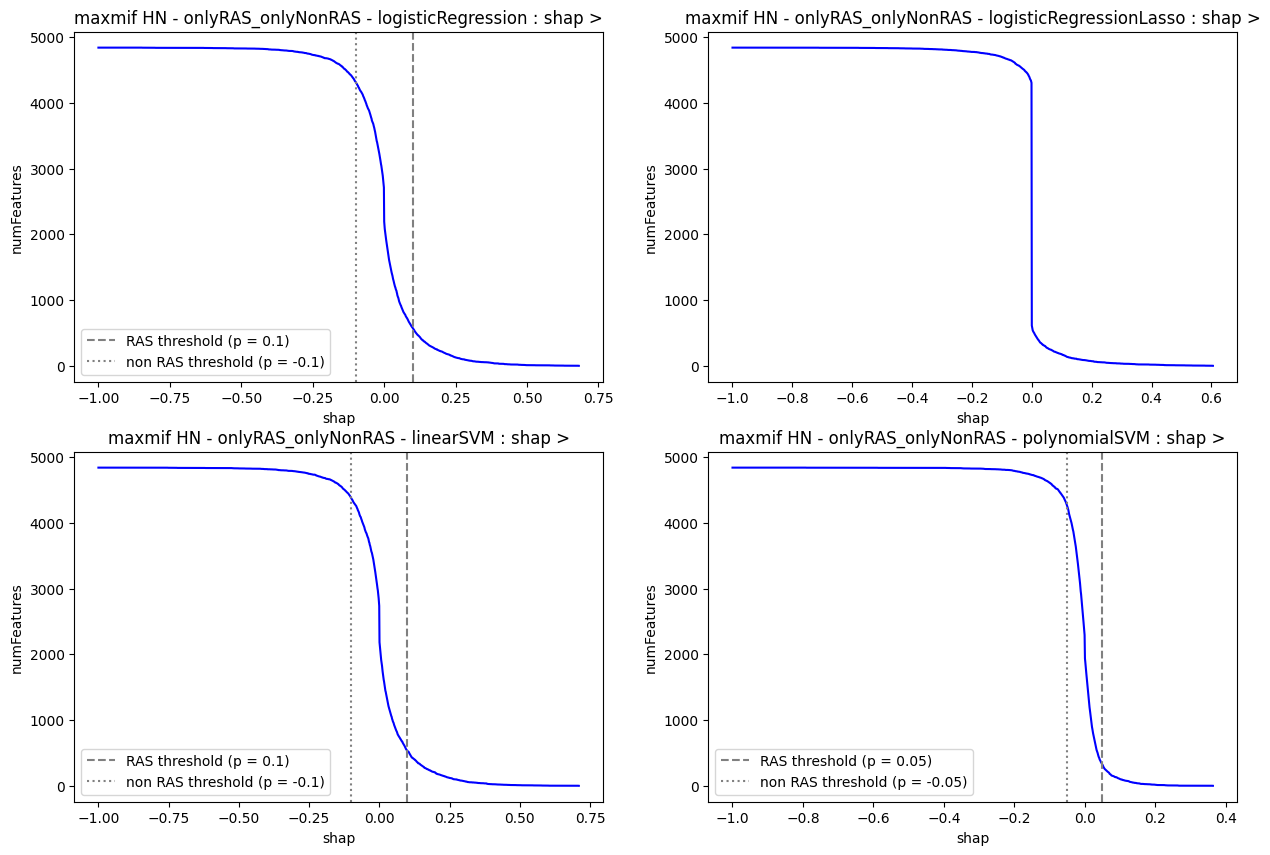

In [38]:
# plot both in different plots
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
ax = ax.flatten()

ax[0].plot(plot_LR_maxmifHN_oncodriveclustl['shap'], plot_LR_maxmifHN_oncodriveclustl['numFeatures'], color='blue')
ax[0].axvline(x=0.1, color='grey', linestyle='--', label='RAS threshold (p = 0.1)')
ax[0].axvline(x=-0.1, color='grey', linestyle=':', label='non RAS threshold (p = -0.1)')
ax[0].set_xlabel('shap')
ax[0].set_ylabel('numFeatures')
ax[0].set_title('maxmif HN - onlyRAS_onlyNonRAS - logisticRegression : shap >')
ax[0].legend()

ax[1].plot(plot_LRl_maxmifHN_oncodriveclustl['shap'], plot_LRl_maxmifHN_oncodriveclustl['numFeatures'], color='blue')
ax[1].set_xlabel('shap')
ax[1].set_ylabel('numFeatures')
ax[1].set_title('maxmif HN - onlyRAS_onlyNonRAS - logisticRegressionLasso : shap >')

ax[2].plot(plot_lSVM_maxmifHN_oncodriveclustl['shap'], plot_lSVM_maxmifHN_oncodriveclustl['numFeatures'], color='blue')
ax[2].axvline(x=0.1, color='grey', linestyle='--', label='RAS threshold (p = 0.1)')
ax[2].axvline(x=-0.1, color='grey', linestyle=':', label='non RAS threshold (p = -0.1)')
ax[2].set_xlabel('shap')
ax[2].set_ylabel('numFeatures')
ax[2].set_title('maxmif HN - onlyRAS_onlyNonRAS - linearSVM : shap >')
ax[2].legend()

ax[3].plot(plot_pSVM_maxmifHN_oncodriveclustl['shap'], plot_pSVM_maxmifHN_oncodriveclustl['numFeatures'], color='blue')
ax[3].axvline(x=0.05, color='grey', linestyle='--', label='RAS threshold (p = 0.05)')
ax[3].axvline(x=-0.05, color='grey', linestyle=':', label='non RAS threshold (p = -0.05)')
ax[3].set_xlabel('shap')
ax[3].set_ylabel('numFeatures')
ax[3].set_title('maxmif HN - onlyRAS_onlyNonRAS - polynomialSVM : shap >')
ax[3].legend()

plt.savefig('data/plots/fia/s_oncodriveclustl_thresholds.png')
plt.show()

#### significant features

In [39]:
RAS_significantFeatures_LR_maxmifHN_oncodriveclustl = set(importance_maxmifHN_oncodriveclustl[importance_maxmifHN_oncodriveclustl['LR shap'] > 0.1]['feature'])
RAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl = set(importance_maxmifHN_oncodriveclustl[importance_maxmifHN_oncodriveclustl['lSVM shap'] > 0.1]['feature'])
RAS_significantFeatures_LRl_maxmifHN_oncodriveclustl = set(importance_maxmifHN_oncodriveclustl[importance_maxmifHN_oncodriveclustl['LRl shap'] > 0]['feature'])
RAS_significantFeatures_pSVM_maxmifHN_oncodriveclustl = set(importance_maxmifHN_oncodriveclustl[importance_maxmifHN_oncodriveclustl['pSVM shap'] > 0.05]['feature'])

len(RAS_significantFeatures_LR_maxmifHN_oncodriveclustl), len(RAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl), len(RAS_significantFeatures_LRl_maxmifHN_oncodriveclustl), len(RAS_significantFeatures_pSVM_maxmifHN_oncodriveclustl)

(580, 529, 659, 320)

In [40]:
print("LR & lSVM:\t\t", len(RAS_significantFeatures_LR_maxmifHN_oncodriveclustl & RAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl))
print("LR & LRl:\t\t", len(RAS_significantFeatures_LR_maxmifHN_oncodriveclustl & RAS_significantFeatures_LRl_maxmifHN_oncodriveclustl))
print("LR & pSVM:\t\t", len(RAS_significantFeatures_LR_maxmifHN_oncodriveclustl & RAS_significantFeatures_pSVM_maxmifHN_oncodriveclustl))
print("lSVM & LRl:\t\t", len(RAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl & RAS_significantFeatures_LRl_maxmifHN_oncodriveclustl))
print("lSVM & pSVM:\t\t", len(RAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl & RAS_significantFeatures_pSVM_maxmifHN_oncodriveclustl))
print("LRl & pSVM:\t\t", len(RAS_significantFeatures_LRl_maxmifHN_oncodriveclustl & RAS_significantFeatures_pSVM_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl:\t", len(RAS_significantFeatures_LR_maxmifHN_oncodriveclustl & RAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl & RAS_significantFeatures_LRl_maxmifHN_oncodriveclustl))
print("LR & lSVM & pSVM:\t", len(RAS_significantFeatures_LR_maxmifHN_oncodriveclustl & RAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl & RAS_significantFeatures_pSVM_maxmifHN_oncodriveclustl))
print("LR & LRl & pSVM:\t", len(RAS_significantFeatures_LR_maxmifHN_oncodriveclustl & RAS_significantFeatures_LRl_maxmifHN_oncodriveclustl & RAS_significantFeatures_pSVM_maxmifHN_oncodriveclustl))
print("lSVM & LRl & pSVM:\t", len(RAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl & RAS_significantFeatures_LRl_maxmifHN_oncodriveclustl & RAS_significantFeatures_pSVM_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl & pSVM:\t", len(RAS_significantFeatures_LR_maxmifHN_oncodriveclustl & RAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl & RAS_significantFeatures_LRl_maxmifHN_oncodriveclustl & RAS_significantFeatures_pSVM_maxmifHN_oncodriveclustl))

LR & lSVM:		 506
LR & LRl:		 352
LR & pSVM:		 138
lSVM & LRl:		 330
lSVM & pSVM:		 133
LRl & pSVM:		 127
LR & lSVM & LRl:	 325
LR & lSVM & pSVM:	 131
LR & LRl & pSVM:	 89
lSVM & LRl & pSVM:	 89
LR & lSVM & LRl & pSVM:	 88


In [41]:
nonRAS_significantFeatures_LR_maxmifHN_oncodriveclustl = set(importance_maxmifHN_oncodriveclustl[importance_maxmifHN_oncodriveclustl['LR shap'] < -0.1]['feature'])
nonRAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl = set(importance_maxmifHN_oncodriveclustl[importance_maxmifHN_oncodriveclustl['lSVM shap'] < -0.1]['feature'])
nonRAS_significantFeatures_LRl_maxmifHN_oncodriveclustl = set(importance_maxmifHN_oncodriveclustl[importance_maxmifHN_oncodriveclustl['LRl shap'] < 0]['feature'])
nonRAS_significantFeatures_pSVM_maxmifHN_oncodriveclustl = set(importance_maxmifHN_oncodriveclustl[importance_maxmifHN_oncodriveclustl['pSVM shap'] < -0.05]['feature'])
len(nonRAS_significantFeatures_LR_maxmifHN_oncodriveclustl), len(nonRAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl), len(nonRAS_significantFeatures_LRl_maxmifHN_oncodriveclustl), len(nonRAS_significantFeatures_pSVM_maxmifHN_oncodriveclustl)

(521, 466, 600, 589)

In [42]:
print("LR & lSVM:\t\t", len(nonRAS_significantFeatures_LR_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl))
print("LR & LRl:\t\t", len(nonRAS_significantFeatures_LR_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_LRl_maxmifHN_oncodriveclustl))
print("LR & pSVM:\t\t", len(nonRAS_significantFeatures_LR_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_pSVM_maxmifHN_oncodriveclustl))
print("lSVM & LRl:\t\t", len(nonRAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_LRl_maxmifHN_oncodriveclustl))
print("lSVM & pSVM:\t\t", len(nonRAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_pSVM_maxmifHN_oncodriveclustl))
print("LRl & pSVM:\t\t", len(nonRAS_significantFeatures_LRl_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_pSVM_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl:\t", len(nonRAS_significantFeatures_LR_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_LRl_maxmifHN_oncodriveclustl))
print("LR & lSVM & pSVM:\t", len(nonRAS_significantFeatures_LR_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_pSVM_maxmifHN_oncodriveclustl))
print("LR & LRl & pSVM:\t", len(nonRAS_significantFeatures_LR_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_LRl_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_pSVM_maxmifHN_oncodriveclustl))
print("lSVM & LRl & pSVM:\t", len(nonRAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_LRl_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_pSVM_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl & pSVM:\t", len(nonRAS_significantFeatures_LR_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_LRl_maxmifHN_oncodriveclustl & nonRAS_significantFeatures_pSVM_maxmifHN_oncodriveclustl))

LR & lSVM:		 438
LR & LRl:		 289
LR & pSVM:		 199
lSVM & LRl:		 265
lSVM & pSVM:		 186
LRl & pSVM:		 225
LR & lSVM & LRl:	 258
LR & lSVM & pSVM:	 180
LR & LRl & pSVM:	 142
lSVM & LRl & pSVM:	 134
LR & lSVM & LRl & pSVM:	 130


#### RAS-significant transcriptomic features

In [43]:
RAS_significantTranscriptomic_LR_maxmifHN_oncodriveclustl = set([
    f for f in RAS_significantFeatures_LR_maxmifHN_oncodriveclustl 
    if not ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
RAS_significantTranscriptomic_lSVM_maxmifHN_oncodriveclustl = set([
    f for f in RAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl 
    if not ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
RAS_significantTranscriptomic_LRl_maxmifHN_oncodriveclustl = set([
    f for f in RAS_significantFeatures_LRl_maxmifHN_oncodriveclustl
    if not ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
RAS_significantTranscriptomic_pSVM_maxmifHN_oncodriveclustl = set([
    f for f in RAS_significantFeatures_pSVM_maxmifHN_oncodriveclustl 
    if not ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
len(RAS_significantTranscriptomic_LR_maxmifHN_oncodriveclustl), len(RAS_significantTranscriptomic_lSVM_maxmifHN_oncodriveclustl), len(RAS_significantTranscriptomic_LRl_maxmifHN_oncodriveclustl), len(RAS_significantTranscriptomic_pSVM_maxmifHN_oncodriveclustl)

(293, 269, 308, 145)

In [44]:
print("LR & lSVM:\t\t", len(RAS_significantTranscriptomic_LR_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_lSVM_maxmifHN_oncodriveclustl))
print("LR & LRl:\t\t", len(RAS_significantTranscriptomic_LR_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_LRl_maxmifHN_oncodriveclustl))
print("LR & pSVM:\t\t", len(RAS_significantTranscriptomic_LR_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_pSVM_maxmifHN_oncodriveclustl))
print("lSVM & LRl:\t\t", len(RAS_significantTranscriptomic_lSVM_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_LRl_maxmifHN_oncodriveclustl))
print("lSVM & pSVM:\t\t", len(RAS_significantTranscriptomic_lSVM_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_pSVM_maxmifHN_oncodriveclustl))
print("LRl & pSVM:\t\t", len(RAS_significantTranscriptomic_LRl_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_pSVM_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl:\t", len(RAS_significantTranscriptomic_LR_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_lSVM_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_LRl_maxmifHN_oncodriveclustl))
print("LR & lSVM & pSVM:\t", len(RAS_significantTranscriptomic_LR_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_lSVM_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_pSVM_maxmifHN_oncodriveclustl))
print("LR & LRl & pSVM:\t", len(RAS_significantTranscriptomic_LR_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_LRl_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_pSVM_maxmifHN_oncodriveclustl))
print("lSVM & LRl & pSVM:\t", len(RAS_significantTranscriptomic_lSVM_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_LRl_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_pSVM_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl & pSVM:\t", len(RAS_significantTranscriptomic_LR_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_lSVM_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_LRl_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_pSVM_maxmifHN_oncodriveclustl))

LR & lSVM:		 258
LR & LRl:		 177
LR & pSVM:		 74
lSVM & LRl:		 168
lSVM & pSVM:		 73
LRl & pSVM:		 65
LR & lSVM & LRl:	 164
LR & lSVM & pSVM:	 72
LR & LRl & pSVM:	 51
lSVM & LRl & pSVM:	 52
LR & lSVM & LRl & pSVM:	 51


In [45]:
importance_maxmifHN_oncodriveclustl[importance_maxmifHN_oncodriveclustl['feature'].isin(RAS_significantTranscriptomic_LR_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_lSVM_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_LRl_maxmifHN_oncodriveclustl & RAS_significantTranscriptomic_pSVM_maxmifHN_oncodriveclustl)]

,feature,gene,from,LR shap,lSVM shap,LRl shap,pSVM shap,sum
785,IGSF10_tran,IGSF10,nonRAS,0.655721,0.709451,0.369412,0.179953,0.487041
851,KIAA0319_tran,KIAA0319,nonRAS,0.561549,0.636973,0.427707,0.229509,0.472083
1581,SERPINE2_tran,SERPINE2,nonRAS,0.595515,0.505765,0.355119,0.126652,0.402714
1573,SEMA7A_tran,SEMA7A,nonRAS,0.421170,0.385640,0.350652,0.226451,0.352055
348,CPS1_tran,CPS1,nonRAS,0.629887,0.568640,0.013697,0.131841,0.341918
63,ALDH1L2_tran,ALDH1L2,nonRAS,0.489262,0.484001,0.094927,0.226229,0.329289
2024,ZNF600_tran,ZNF600,nonRAS,0.419844,0.396916,0.206610,0.126283,0.292462
1685,SPRED1_tran,SPRED1,nonRAS,0.431592,0.400569,0.186948,0.091346,0.282490
640,GK_tran,GK,nonRAS,0.306220,0.296211,0.217061,0.264383,0.275728
855,KIF27_tran,KIF27,nonRAS,0.256247,0.245401,0.282193,0.201709,0.250715


#### RAS-significant mutational features

In [46]:
RAS_significantMutations_LR_maxmifHN_oncodriveclustl  = set([
    f for f in RAS_significantFeatures_LR_maxmifHN_oncodriveclustl 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
RAS_significantMutations_lSVM_maxmifHN_oncodriveclustl  = set([
    f for f in RAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
RAS_significantMutations_LRl_maxmifHN_oncodriveclustl  = set([
    f for f in RAS_significantFeatures_LRl_maxmifHN_oncodriveclustl 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
RAS_significantMutations_pSVM_maxmifHN_oncodriveclustl  = set([
    f for f in RAS_significantFeatures_pSVM_maxmifHN_oncodriveclustl 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
len(RAS_significantMutations_LR_maxmifHN_oncodriveclustl), len(RAS_significantMutations_lSVM_maxmifHN_oncodriveclustl), len(RAS_significantMutations_LRl_maxmifHN_oncodriveclustl), len(RAS_significantMutations_pSVM_maxmifHN_oncodriveclustl)

(287, 260, 351, 175)

In [47]:
print("LR & lSVM:\t\t", len(RAS_significantMutations_LR_maxmifHN_oncodriveclustl & RAS_significantMutations_lSVM_maxmifHN_oncodriveclustl))
print("LR & LRl:\t\t", len(RAS_significantMutations_LR_maxmifHN_oncodriveclustl & RAS_significantMutations_LRl_maxmifHN_oncodriveclustl))
print("LR & pSVM:\t\t", len(RAS_significantMutations_LR_maxmifHN_oncodriveclustl & RAS_significantMutations_pSVM_maxmifHN_oncodriveclustl))
print("lSVM & LRl:\t\t", len(RAS_significantMutations_lSVM_maxmifHN_oncodriveclustl & RAS_significantMutations_LRl_maxmifHN_oncodriveclustl))
print("lSVM & pSVM:\t\t", len(RAS_significantMutations_lSVM_maxmifHN_oncodriveclustl & RAS_significantMutations_pSVM_maxmifHN_oncodriveclustl))
print("LRl & pSVM:\t\t", len(RAS_significantMutations_LRl_maxmifHN_oncodriveclustl & RAS_significantMutations_pSVM_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl:\t", len(RAS_significantMutations_LR_maxmifHN_oncodriveclustl & RAS_significantMutations_lSVM_maxmifHN_oncodriveclustl & RAS_significantMutations_LRl_maxmifHN_oncodriveclustl))
print("LR & lSVM & pSVM:\t", len(RAS_significantMutations_LR_maxmifHN_oncodriveclustl & RAS_significantMutations_lSVM_maxmifHN_oncodriveclustl & RAS_significantMutations_pSVM_maxmifHN_oncodriveclustl))
print("LR & LRl & pSVM:\t", len(RAS_significantMutations_LR_maxmifHN_oncodriveclustl & RAS_significantMutations_LRl_maxmifHN_oncodriveclustl & RAS_significantMutations_pSVM_maxmifHN_oncodriveclustl))
print("lSVM & LRl & pSVM:\t", len(RAS_significantMutations_lSVM_maxmifHN_oncodriveclustl & RAS_significantMutations_LRl_maxmifHN_oncodriveclustl & RAS_significantMutations_pSVM_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl & pSVM:\t", len(RAS_significantMutations_LR_maxmifHN_oncodriveclustl & RAS_significantMutations_lSVM_maxmifHN_oncodriveclustl & RAS_significantMutations_LRl_maxmifHN_oncodriveclustl & RAS_significantMutations_pSVM_maxmifHN_oncodriveclustl))

LR & lSVM:		 248
LR & LRl:		 175
LR & pSVM:		 64
lSVM & LRl:		 162
lSVM & pSVM:		 60
LRl & pSVM:		 62
LR & lSVM & LRl:	 161
LR & lSVM & pSVM:	 59
LR & LRl & pSVM:	 38
lSVM & LRl & pSVM:	 37
LR & lSVM & LRl & pSVM:	 37


In [48]:
importance_maxmifHN_oncodriveclustl[importance_maxmifHN_oncodriveclustl['feature'].isin(RAS_significantMutations_LR_maxmifHN_oncodriveclustl & RAS_significantMutations_lSVM_maxmifHN_oncodriveclustl & RAS_significantMutations_LRl_maxmifHN_oncodriveclustl & RAS_significantMutations_pSVM_maxmifHN_oncodriveclustl)]

,feature,gene,from,LR shap,lSVM shap,LRl shap,pSVM shap,sum
4519,TFRC_noCluster,TFRC,nonRAS,0.681195,0.384532,0.598277,0.110808,0.451496
2923,GALNT5_noCluster,GALNT5,RAS,0.615297,0.603008,0.327267,0.191107,0.441795
3715,PAN2_noCluster,PAN2,nonRAS,0.455667,0.487920,0.442033,0.112863,0.381201
3812,PIK3R4_noCluster,PIK3R4,nonRAS,0.378704,0.362052,0.347427,0.363284,0.369240
2434,CEACAM8_noCluster,CEACAM8,nonRAS,0.415254,0.415653,0.326368,0.199485,0.345148
4161,RTN2_noCluster,RTN2,RAS,0.420643,0.422215,0.111604,0.098200,0.267788
2857,FGF23_noCluster,FGF23,nonRAS,0.320345,0.337763,0.189891,0.188313,0.263628
2044,AASDH_noCluster,AASDH,nonRAS,0.297087,0.255186,0.117911,0.292941,0.245010
3966,PSME4_noCluster,PSME4,nonRAS,0.285832,0.277973,0.283452,0.085264,0.237225
2904,FUS_noCluster,FUS,RAS,0.300626,0.302936,0.192095,0.111677,0.230818


#### comparison with maxmif significance in RAS/nonRAS

In [49]:
RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in RAS_significantMutations_LR_maxmifHN_oncodriveclustl
])
RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in RAS_significantMutations_lSVM_maxmifHN_oncodriveclustl
])
RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f)
    for f in RAS_significantMutations_LRl_maxmifHN_oncodriveclustl
])
RAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in RAS_significantMutations_pSVM_maxmifHN_oncodriveclustl
])
len(RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl), len(RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl), len(RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl), len(RAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl)

(284, 258, 343, 175)

In [50]:
print("LR & lSVM:\t\t", len(RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl & RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl))
print("LR & LRl:\t\t", len(RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl & RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl))
print("LR & pSVM:\t\t", len(RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl & RAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl))
print("lSVM & LRl:\t\t", len(RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl & RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl))
print("lSVM & pSVM:\t\t", len(RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl & RAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl))
print("LRl & pSVM:\t\t", len(RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl & RAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl:\t", len(RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl & RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl & RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl))
print("LR & lSVM & pSVM:\t", len(RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl & RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl & RAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl))
print("LR & LRl & pSVM:\t", len(RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl & RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl & RAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl))
print("lSVM & LRl & pSVM:\t", len(RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl & RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl & RAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl & pSVM:\t", len(RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl & RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl & RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl & RAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl))

LR & lSVM:		 246
LR & LRl:		 175
LR & pSVM:		 64
lSVM & LRl:		 162
lSVM & pSVM:		 60
LRl & pSVM:		 63
LR & lSVM & LRl:	 161
LR & lSVM & pSVM:	 59
LR & LRl & pSVM:	 39
lSVM & LRl & pSVM:	 38
LR & lSVM & LRl & pSVM:	 38


In [51]:
nonRAS_significantMutations_LR_maxmifHN_oncodriveclustl  = set([
    f for f in nonRAS_significantFeatures_LR_maxmifHN_oncodriveclustl 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
nonRAS_significantMutations_lSVM_maxmifHN_oncodriveclustl  = set([
    f for f in nonRAS_significantFeatures_lSVM_maxmifHN_oncodriveclustl 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
nonRAS_significantMutations_LRl_maxmifHN_oncodriveclustl  = set([
    f for f in nonRAS_significantFeatures_LRl_maxmifHN_oncodriveclustl 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
nonRAS_significantMutations_pSVM_maxmifHN_oncodriveclustl  = set([
    f for f in nonRAS_significantFeatures_pSVM_maxmifHN_oncodriveclustl 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])

nonRAS_significantMutGenes_LR_maxmifHN_oncodriveclustl = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in nonRAS_significantMutations_LR_maxmifHN_oncodriveclustl
])
nonRAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in nonRAS_significantMutations_lSVM_maxmifHN_oncodriveclustl
])
nonRAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in nonRAS_significantMutations_LRl_maxmifHN_oncodriveclustl
])
nonRAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl = set([
    re.sub(r'(_noCluster|_\d+_\d+)$', '', f) 
    for f in nonRAS_significantMutations_pSVM_maxmifHN_oncodriveclustl
])

len(nonRAS_significantMutGenes_LR_maxmifHN_oncodriveclustl), len(nonRAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl), len(nonRAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl), len(nonRAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl)

(233, 213, 321, 285)

In [52]:
print("LR & lSVM:\t\t", len(nonRAS_significantMutGenes_LR_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl))
print("LR & LRl:\t\t", len(nonRAS_significantMutGenes_LR_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl))
print("LR & pSVM:\t\t", len(nonRAS_significantMutGenes_LR_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl))
print("lSVM & LRl:\t\t", len(nonRAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl))
print("lSVM & pSVM:\t\t", len(nonRAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl))
print("LRl & pSVM:\t\t", len(nonRAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl:\t", len(nonRAS_significantMutGenes_LR_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl))
print("LR & lSVM & pSVM:\t", len(nonRAS_significantMutGenes_LR_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl))
print("LR & LRl & pSVM:\t", len(nonRAS_significantMutGenes_LR_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl))
print("lSVM & LRl & pSVM:\t", len(nonRAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl & pSVM:\t", len(nonRAS_significantMutGenes_LR_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl & nonRAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl))

LR & lSVM:		 199
LR & LRl:		 140
LR & pSVM:		 84
lSVM & LRl:		 132
lSVM & pSVM:		 84
LRl & pSVM:		 109
LR & lSVM & LRl:	 125
LR & lSVM & pSVM:	 79
LR & LRl & pSVM:	 58
lSVM & LRl & pSVM:	 57
LR & lSVM & LRl & pSVM:	 54


In [53]:
# LR: RAS -> RAS
odc_LR_RAS_RAS = [f for f in RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl if f in onlyRAS]
# LR: nonRAS -> RAS
odc_LR_nonRAS_RAS = [f for f in RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl if f in onlyNonRAS]
# LR: RAS -> nonRAS
odc_LR_RAS_nonRAS = [f for f in nonRAS_significantMutGenes_LR_maxmifHN_oncodriveclustl if f in onlyRAS]
# LR: nonRAS -> nonRAS
odc_LR_nonRAS_nonRAS = [f for f in nonRAS_significantMutGenes_LR_maxmifHN_oncodriveclustl if f in onlyNonRAS]
len(odc_LR_RAS_RAS), len(odc_LR_nonRAS_RAS), len(odc_LR_RAS_nonRAS), len(odc_LR_nonRAS_nonRAS)

(38, 246, 54, 179)

In [54]:
# lSVM: RAS -> RAS
odc_lSVM_RAS_RAS = [f for f in RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl if f in onlyRAS]
# lSVM: nonRAS -> RAS
odc_lSVM_nonRAS_RAS = [f for f in RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl if f in onlyNonRAS]
# lSVM: RAS -> nonRAS
odc_lSVM_RAS_nonRAS = [f for f in nonRAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl if f in onlyRAS]
# lSVM: nonRAS -> nonRAS
odc_lSVM_nonRAS_nonRAS = [f for f in nonRAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl if f in onlyNonRAS]
len(odc_lSVM_RAS_RAS), len(odc_lSVM_nonRAS_RAS), len(odc_lSVM_RAS_nonRAS), len(odc_lSVM_nonRAS_nonRAS)

(32, 226, 48, 165)

In [55]:
# LRl: RAS -> RAS
odc_LRl_RAS_RAS = [f for f in RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl if f in onlyRAS]
# LRl: nonRAS -> RAS
odc_LRl_nonRAS_RAS = [f for f in RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl if f in onlyNonRAS]
# LRl: RAS -> nonRAS
odc_LRl_RAS_nonRAS = [f for f in nonRAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl if f in onlyRAS]
# LRl: nonRAS -> nonRAS
odc_LRl_nonRAS_nonRAS = [f for f in nonRAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl if f in onlyNonRAS]
len(odc_LRl_RAS_RAS), len(odc_LRl_nonRAS_RAS), len(odc_LRl_RAS_nonRAS), len(odc_LRl_nonRAS_nonRAS)

(51, 292, 59, 262)

In [56]:
# pSVM: RAS -> RAS
odc_pSVM_RAS_RAS = [f for f in RAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl if f in onlyRAS]
# pSVM: nonRAS -> RAS
odc_pSVM_nonRAS_RAS = [f for f in RAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl if f in onlyNonRAS]
# pSVM: RAS -> nonRAS
odc_pSVM_RAS_nonRAS = [f for f in nonRAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl if f in onlyRAS]
# pSVM: nonRAS -> nonRAS
odc_pSVM_nonRAS_nonRAS = [f for f in nonRAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl if f in onlyNonRAS]
len(odc_pSVM_RAS_RAS), len(odc_pSVM_nonRAS_RAS), len(odc_pSVM_RAS_nonRAS), len(odc_pSVM_nonRAS_nonRAS)

(47, 128, 11, 274)

#### RAS-significant mutational clustered features

In [57]:
RAS_significantClusters_LR_maxmifHN_oncodriveclustl = set([
    f for f in RAS_significantMutations_LR_maxmifHN_oncodriveclustl
    if re.search(r'_\d+_\d+', f) 
])
RAS_significantClusters_lSVM_maxmifHN_oncodriveclustl = set([
    f for f in RAS_significantMutations_lSVM_maxmifHN_oncodriveclustl
    if re.search(r'_\d+_\d+', f) 
])
RAS_significantClusters_LRl_maxmifHN_oncodriveclustl = set([
    f for f in RAS_significantMutations_LRl_maxmifHN_oncodriveclustl
    if re.search(r'_\d+_\d+', f) 
])
RAS_significantClusters_pSVM_maxmifHN_oncodriveclustl = set([
    f for f in RAS_significantMutations_pSVM_maxmifHN_oncodriveclustl
    if re.search(r'_\d+_\d+', f) 
])

len(RAS_significantClusters_LR_maxmifHN_oncodriveclustl), len(RAS_significantClusters_lSVM_maxmifHN_oncodriveclustl), len(RAS_significantClusters_LRl_maxmifHN_oncodriveclustl), len(RAS_significantClusters_pSVM_maxmifHN_oncodriveclustl)

(24, 21, 45, 12)

In [58]:
print("LR & lSVM:\t\t", len(RAS_significantClusters_LR_maxmifHN_oncodriveclustl & RAS_significantClusters_lSVM_maxmifHN_oncodriveclustl))
print("LR & LRl:\t\t", len(RAS_significantClusters_LR_maxmifHN_oncodriveclustl & RAS_significantClusters_LRl_maxmifHN_oncodriveclustl))
print("LR & pSVM:\t\t", len(RAS_significantClusters_LR_maxmifHN_oncodriveclustl & RAS_significantClusters_pSVM_maxmifHN_oncodriveclustl))
print("lSVM & LRl:\t\t", len(RAS_significantClusters_lSVM_maxmifHN_oncodriveclustl & RAS_significantClusters_LRl_maxmifHN_oncodriveclustl))
print("lSVM & pSVM:\t\t", len(RAS_significantClusters_lSVM_maxmifHN_oncodriveclustl & RAS_significantClusters_pSVM_maxmifHN_oncodriveclustl))
print("LRl & pSVM:\t\t", len(RAS_significantClusters_LRl_maxmifHN_oncodriveclustl & RAS_significantClusters_pSVM_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl:\t", len(RAS_significantClusters_LR_maxmifHN_oncodriveclustl & RAS_significantClusters_lSVM_maxmifHN_oncodriveclustl & RAS_significantClusters_LRl_maxmifHN_oncodriveclustl))
print("LR & lSVM & pSVM:\t", len(RAS_significantClusters_LR_maxmifHN_oncodriveclustl & RAS_significantClusters_lSVM_maxmifHN_oncodriveclustl & RAS_significantClusters_pSVM_maxmifHN_oncodriveclustl))
print("LR & LRl & pSVM:\t", len(RAS_significantClusters_LR_maxmifHN_oncodriveclustl & RAS_significantClusters_LRl_maxmifHN_oncodriveclustl & RAS_significantClusters_pSVM_maxmifHN_oncodriveclustl))
print("lSVM & LRl & pSVM:\t", len(RAS_significantClusters_lSVM_maxmifHN_oncodriveclustl & RAS_significantClusters_LRl_maxmifHN_oncodriveclustl & RAS_significantClusters_pSVM_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl & pSVM:\t", len(RAS_significantClusters_LR_maxmifHN_oncodriveclustl & RAS_significantClusters_lSVM_maxmifHN_oncodriveclustl & RAS_significantClusters_LRl_maxmifHN_oncodriveclustl & RAS_significantClusters_pSVM_maxmifHN_oncodriveclustl))

LR & lSVM:		 21
LR & LRl:		 15
LR & pSVM:		 4
lSVM & LRl:		 13
lSVM & pSVM:		 4
LRl & pSVM:		 3
LR & lSVM & LRl:	 13
LR & lSVM & pSVM:	 4
LR & LRl & pSVM:	 2
lSVM & LRl & pSVM:	 2
LR & lSVM & LRl & pSVM:	 2


In [59]:
importance_maxmifHN_oncodriveclustl[importance_maxmifHN_oncodriveclustl['feature'].isin(RAS_significantClusters_LR_maxmifHN_oncodriveclustl & RAS_significantClusters_lSVM_maxmifHN_oncodriveclustl & RAS_significantClusters_LRl_maxmifHN_oncodriveclustl & RAS_significantClusters_pSVM_maxmifHN_oncodriveclustl)]

,feature,gene,from,LR shap,lSVM shap,LRl shap,pSVM shap,sum
3986,PUM1_31418205_31418213,PUM1,nonRAS,0.189854,0.203778,0.170376,0.189022,0.191564
2892,FRMD4A_13735926_13735926,FRMD4A,RAS,0.175132,0.155412,0.150116,0.073449,0.140960


significant clusters' genes

In [60]:
RAS_significantClusterGenes_LR_maxmifHN_oncodriveclustl = set([
    re.sub(r'_\d+_\d+$', '', f) 
    for f in RAS_significantClusters_LR_maxmifHN_oncodriveclustl
])
RAS_significantClusterGenes_lSVM_maxmifHN_oncodriveclustl = set([
    re.sub(r'_\d+_\d+$', '', f) 
    for f in RAS_significantClusters_lSVM_maxmifHN_oncodriveclustl
])
RAS_significantClusterGenes_LRl_maxmifHN_oncodriveclustl = set([
    re.sub(r'_\d+_\d+$', '', f) 
    for f in RAS_significantClusters_LRl_maxmifHN_oncodriveclustl
])
RAS_significantClusterGenes_pSVM_maxmifHN_oncodriveclustl = set([
    re.sub(r'_\d+_\d+$', '', f) 
    for f in RAS_significantClusters_pSVM_maxmifHN_oncodriveclustl
])

len(RAS_significantClusterGenes_LR_maxmifHN_oncodriveclustl), len(RAS_significantClusterGenes_lSVM_maxmifHN_oncodriveclustl), len(RAS_significantClusterGenes_LRl_maxmifHN_oncodriveclustl), len(RAS_significantClusterGenes_pSVM_maxmifHN_oncodriveclustl)

(24, 21, 44, 12)

In [61]:
print("LR & lSVM:\t\t", len(RAS_significantClusterGenes_LR_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_lSVM_maxmifHN_oncodriveclustl))
print("LR & LRl:\t\t", len(RAS_significantClusterGenes_LR_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_LRl_maxmifHN_oncodriveclustl))
print("LR & pSVM:\t\t", len(RAS_significantClusterGenes_LR_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_pSVM_maxmifHN_oncodriveclustl))
print("lSVM & LRl:\t\t", len(RAS_significantClusterGenes_lSVM_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_LRl_maxmifHN_oncodriveclustl))
print("lSVM & pSVM:\t\t", len(RAS_significantClusterGenes_lSVM_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_pSVM_maxmifHN_oncodriveclustl))
print("LRl & pSVM:\t\t", len(RAS_significantClusterGenes_LRl_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_pSVM_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl:\t", len(RAS_significantClusterGenes_LR_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_lSVM_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_LRl_maxmifHN_oncodriveclustl))
print("LR & lSVM & pSVM:\t", len(RAS_significantClusterGenes_LR_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_lSVM_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_pSVM_maxmifHN_oncodriveclustl))
print("LR & LRl & pSVM:\t", len(RAS_significantClusterGenes_LR_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_LRl_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_pSVM_maxmifHN_oncodriveclustl))
print("lSVM & LRl & pSVM:\t", len(RAS_significantClusterGenes_lSVM_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_LRl_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_pSVM_maxmifHN_oncodriveclustl))

print("LR & lSVM & LRl & pSVM:\t", len(RAS_significantClusterGenes_LR_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_lSVM_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_LRl_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_pSVM_maxmifHN_oncodriveclustl))

LR & lSVM:		 21
LR & LRl:		 15
LR & pSVM:		 4
lSVM & LRl:		 13
lSVM & pSVM:		 4
LRl & pSVM:		 3
LR & lSVM & LRl:	 13
LR & lSVM & pSVM:	 4
LR & LRl & pSVM:	 2
lSVM & LRl & pSVM:	 2
LR & lSVM & LRl & pSVM:	 2


In [62]:
importance_maxmifHN_oncodriveclustl[importance_maxmifHN_oncodriveclustl['gene'].isin(RAS_significantClusterGenes_LR_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_lSVM_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_LRl_maxmifHN_oncodriveclustl & RAS_significantClusterGenes_pSVM_maxmifHN_oncodriveclustl)]

,feature,gene,from,LR shap,lSVM shap,LRl shap,pSVM shap,sum
3986,PUM1_31418205_31418213,PUM1,nonRAS,0.189854,0.203778,0.170376,0.189022,0.191564
2892,FRMD4A_13735926_13735926,FRMD4A,RAS,0.175132,0.155412,0.150116,0.073449,0.140960
2893,FRMD4A_noCluster,FRMD4A,RAS,0.117778,0.115246,0.055801,0.032372,0.081710
3987,PUM1_noCluster,PUM1,nonRAS,0.050013,0.020145,0.000000,0.018658,0.022594
1387,PUM1_tran,PUM1,nonRAS,0.001139,0.001506,0.000000,0.022970,0.006517
594,FRMD4A_tran,FRMD4A,RAS,-0.008499,-0.002295,0.000000,0.002178,-0.002192


## both

In [63]:
importance_maxmifHN = pd.merge(importance_maxmifHN_mutclust.drop(columns=['sum']), importance_maxmifHN_oncodriveclustl.drop(columns=['sum']), on=['feature', 'gene', 'from'], how='outer', suffixes=(' - mc', ' - odc'))

numerical_cols = importance_maxmifHN.select_dtypes(include=['number']).columns
importance_maxmifHN['sum'] = importance_maxmifHN[numerical_cols].sum(axis=1)
importance_maxmifHN[['sum']] = importance_maxmifHN[['sum']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
importance_maxmifHN = importance_maxmifHN.sort_values('sum', ascending=False)

importance_maxmifHN

,feature,gene,from,LR shap - mc,LRl shap - mc,lSVM shap - mc,RF shap,LR shap - odc,lSVM shap - odc,LRl shap - odc,pSVM shap,sum
1999,IGSF10_tran,IGSF10,nonRAS,0.671551,0.732286,0.713882,-0.007158,0.655721,0.709451,0.369412,0.179953,0.593695
4449,TFRC_noCluster,TFRC,nonRAS,0.721728,0.565662,0.519709,0.000006,0.681195,0.384532,0.598277,0.110808,0.528326
2018,IL6R_noCluster,IL6R,nonRAS,0.530015,0.741162,0.615311,0.016167,0.498182,0.578425,0.536976,-0.007389,0.517549
1564,GALNT5_noCluster,GALNT5,RAS,0.652544,0.380507,0.653866,0.008837,0.615297,0.603008,0.327267,0.191107,0.506277
4018,SLC15A2_noCluster,SLC15A2,nonRAS,0.635821,0.416584,0.642800,-0.009039,0.582460,0.590031,0.605091,-0.052526,0.503149
...,...,...,...,...,...,...,...,...,...,...,...,...
4431,TEAD4_noCluster,TEAD4,nonRAS,-0.615282,-0.345456,-0.638096,0.000000,-0.605595,-0.618813,-0.477510,-0.483322,-0.558144
553,CAPN12_tran,CAPN12,nonRAS,-0.842614,-0.501465,-0.805689,-0.008821,-0.809450,-0.751900,-0.423678,0.087188,-0.598316
576,CBX3_tran,CBX3,RAS,-0.833398,-0.823126,-0.774451,-0.001782,-0.800749,-0.718938,-0.710799,-0.224818,-0.720980
1922,HOXB3_tran,HOXB3,nonRAS,-0.857099,-1.000000,-0.850301,-0.633258,-0.846088,-0.837891,-1.000000,-0.238482,-0.923798


#### RAS-significant transcriptomic features

In [64]:
RAS_significantTranscriptomic_LR_maxmifHN = RAS_significantTranscriptomic_LR_maxmifHN_mutclust & RAS_significantTranscriptomic_LR_maxmifHN_oncodriveclustl
RAS_significantTranscriptomic_lSVM_maxmifHN = RAS_significantTranscriptomic_lSVM_maxmifHN_mutclust & RAS_significantTranscriptomic_lSVM_maxmifHN_oncodriveclustl
RAS_significantTranscriptomic_LRl_maxmifHN = RAS_significantTranscriptomic_LRl_maxmifHN_mutclust & RAS_significantTranscriptomic_LRl_maxmifHN_oncodriveclustl

len(RAS_significantTranscriptomic_LR_maxmifHN), len(RAS_significantTranscriptomic_lSVM_maxmifHN), len(RAS_significantTranscriptomic_LRl_maxmifHN)

(288, 263, 187)

In [65]:
print("LR & lSVM:\t\t", len(RAS_significantTranscriptomic_LR_maxmifHN & RAS_significantTranscriptomic_lSVM_maxmifHN))
print("LR & LRl:\t\t", len(RAS_significantTranscriptomic_LR_maxmifHN & RAS_significantTranscriptomic_LRl_maxmifHN))
print("lSVM & LRl:\t\t", len(RAS_significantTranscriptomic_lSVM_maxmifHN & RAS_significantTranscriptomic_LRl_maxmifHN))

print("LR & lSVM & LRl:\t", len(RAS_significantTranscriptomic_LR_maxmifHN & RAS_significantTranscriptomic_lSVM_maxmifHN & RAS_significantTranscriptomic_LRl_maxmifHN))

LR & lSVM:		 253
LR & LRl:		 125
lSVM & LRl:		 122
LR & lSVM & LRl:	 120


#### RAS-significant mutated gens

In [66]:
RAS_significantMutGenes_LR_maxmifHN = RAS_significantMutGenes_LR_maxmifHN_mutclust & RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl
RAS_significantMutGenes_lSVM_maxmifHN = RAS_significantMutGenes_lSVM_maxmifHN_mutclust & RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl
RAS_significantMutGenes_LRl_maxmifHN = RAS_significantMutGenes_LRl_maxmifHN_mutclust & RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl

len(RAS_significantMutGenes_LR_maxmifHN), len(RAS_significantMutGenes_lSVM_maxmifHN), len(RAS_significantMutGenes_LRl_maxmifHN)

(262, 232, 218)

In [67]:
print("LR & lSVM:\t\t", len(RAS_significantMutGenes_LR_maxmifHN & RAS_significantMutGenes_lSVM_maxmifHN))
print("LR & LRl:\t\t", len(RAS_significantMutGenes_LR_maxmifHN & RAS_significantMutGenes_LRl_maxmifHN))
print("lSVM & LRl:\t\t", len(RAS_significantMutGenes_lSVM_maxmifHN & RAS_significantMutGenes_LRl_maxmifHN))

print("LR & lSVM & LRl:\t", len(RAS_significantMutGenes_LR_maxmifHN & RAS_significantMutGenes_lSVM_maxmifHN & RAS_significantMutGenes_LRl_maxmifHN))

LR & lSVM:		 222
LR & LRl:		 131
lSVM & LRl:		 125
LR & lSVM & LRl:	 125


In [68]:
importance_maxmifHN[importance_maxmifHN['feature'].str.contains(r'(?:_noCluster|_\d+_\d+)$', regex=True) & importance_maxmifHN['gene'].isin(
    RAS_significantMutGenes_LR_maxmifHN & RAS_significantMutGenes_lSVM_maxmifHN & RAS_significantMutGenes_LRl_maxmifHN
    & RAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl)]

,feature,gene,from,LR shap - mc,LRl shap - mc,lSVM shap - mc,RF shap,LR shap - odc,lSVM shap - odc,LRl shap - odc,pSVM shap,sum
4449,TFRC_noCluster,TFRC,nonRAS,7.217276e-01,0.565662,5.197086e-01,0.000006,0.681195,0.384532,0.598277,0.110808,0.528326
1564,GALNT5_noCluster,GALNT5,RAS,6.525439e-01,0.380507,6.538659e-01,0.008837,0.615297,0.603008,0.327267,0.191107,0.506277
2991,PAN2_noCluster,PAN2,nonRAS,4.600479e-01,0.288377,5.008831e-01,-0.004456,0.455667,0.487920,0.442033,0.112863,0.404637
701,CEACAM8_noCluster,CEACAM8,nonRAS,4.447945e-01,0.366298,4.365361e-01,-0.007011,0.415254,0.415653,0.326368,0.199485,0.383108
3167,PIK3R4_noCluster,PIK3R4,nonRAS,4.299769e-01,0.218652,4.153911e-01,0.000000,0.378704,0.362052,0.347427,0.363284,0.371030
3820,RTN2_noCluster,RTN2,RAS,4.760414e-01,0.192185,4.842915e-01,-0.007136,0.420643,0.422215,0.111604,0.098200,0.324207
8,AASDH_noCluster,AASDH,nonRAS,3.272360e-01,0.309497,2.832955e-01,0.009745,0.297087,0.255186,0.117911,0.292941,0.279199
1449,FGF23_noCluster,FGF23,nonRAS,3.279614e-01,0.151880,3.529924e-01,-0.005032,0.320345,0.337763,0.189891,0.188313,0.274953
1528,FUS_noCluster,FUS,RAS,3.133681e-01,0.302531,3.184434e-01,0.000000,0.300626,0.302936,0.192095,0.111677,0.271644
790,CLPX_noCluster,CLPX,nonRAS,2.411521e-01,0.281147,2.284581e-01,-0.010446,0.236419,0.219847,0.188005,0.234552,0.238819


In [69]:
'TNFSF11' in (RAS_significantMutGenes_LR_maxmifHN & RAS_significantMutGenes_lSVM_maxmifHN & RAS_significantMutGenes_LRl_maxmifHN
              & RAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl)

False

In [70]:
import requests

def filter_hugo_symbols(hugo_symbols):
    found_symbols = []
    base_url = "https://idrblab.net/ttd/search/ttd/target?search_api_fulltext="
    
    for symbol in hugo_symbols:
        url = base_url + symbol
        try:
            response = requests.get(url)
            response.raise_for_status()  # Raises an HTTPError if the HTTP request returned an unsuccessful status code
            if "Sorry! Nothing is found" not in response.text:
                found_symbols.append(symbol)
        except requests.exceptions.RequestException as e:
            print(f"Error fetching data for symbol {symbol}: {e}")
    
    return found_symbols

In [71]:
gg =RAS_significantMutGenes_LR_maxmifHN & RAS_significantMutGenes_lSVM_maxmifHN & RAS_significantMutGenes_LRl_maxmifHN & RAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl

In [72]:
# filter_hugo_symbols(gg)

In [73]:
['ASIC2', 'FGF23', 'FUS', 'TFRC', 'ARRB2', 'MSI1', 'CACNA1G', 'GDNF']

['ASIC2', 'FGF23', 'FUS', 'TFRC', 'ARRB2', 'MSI1', 'CACNA1G', 'GDNF']

#### RAS-significant cluster's genes

In [74]:
RAS_significantClusterGenes_LR_maxmifHN = RAS_significantClusterGenes_LR_maxmifHN_mutclust & RAS_significantClusterGenes_LR_maxmifHN_oncodriveclustl
RAS_significantClusterGenes_lSVM_maxmifHN = RAS_significantClusterGenes_lSVM_maxmifHN_mutclust & RAS_significantClusterGenes_lSVM_maxmifHN_oncodriveclustl
RAS_significantClusterGenes_LRl_maxmifHN = RAS_significantClusterGenes_LRl_maxmifHN_mutclust & RAS_significantClusterGenes_LRl_maxmifHN_oncodriveclustl

len(RAS_significantClusterGenes_LR_maxmifHN), len(RAS_significantClusterGenes_lSVM_maxmifHN), len(RAS_significantClusterGenes_LRl_maxmifHN)

(3, 3, 5)

In [75]:
print("LR & lSVM:\t\t", len(RAS_significantClusterGenes_LR_maxmifHN & RAS_significantClusterGenes_lSVM_maxmifHN))
print("LR & LRl:\t\t", len(RAS_significantClusterGenes_LR_maxmifHN & RAS_significantClusterGenes_LRl_maxmifHN))
print("lSVM & LRl:\t\t", len(RAS_significantClusterGenes_lSVM_maxmifHN & RAS_significantClusterGenes_LRl_maxmifHN))

print("LR & lSVM & LRl:\t", len(RAS_significantClusterGenes_LR_maxmifHN & RAS_significantClusterGenes_lSVM_maxmifHN & RAS_significantClusterGenes_LRl_maxmifHN))

LR & lSVM:		 3
LR & LRl:		 2
lSVM & LRl:		 2
LR & lSVM & LRl:	 2


In [76]:
importance_maxmifHN[importance_maxmifHN['feature'].str.contains(r'(?:_\d+_\d+)$', regex=True) & importance_maxmifHN['gene'].isin(
    RAS_significantClusterGenes_LR_maxmifHN & RAS_significantClusterGenes_LRl_maxmifHN & RAS_significantClusterGenes_lSVM_maxmifHN
)].sort_values('gene', ascending=False)

,feature,gene,from,LR shap - mc,LRl shap - mc,lSVM shap - mc,RF shap,LR shap - odc,lSVM shap - odc,LRl shap - odc,pSVM shap,sum
2695,NCOA5_44699131_44699153,NCOA5,nonRAS,NaN,NaN,NaN,NaN,0.248835,0.241910,0.345192,0.0,0.123299
2694,NCOA5_21_28,NCOA5,nonRAS,0.252275,0.189304,0.246448,0.0,NaN,NaN,NaN,NaN,0.101483
807,CNNM1_595_602,CNNM1,nonRAS,0.150796,0.086157,0.149634,0.0,NaN,NaN,NaN,NaN,0.057021
806,CNNM1_101120657_101120678,CNNM1,nonRAS,NaN,NaN,NaN,NaN,0.142320,0.140621,0.099105,0.0,0.056351


## Graphs

#### data composition

In [77]:
trans_mutclust = set([
    f for f in importance_maxmifHN_mutclust['feature'] 
    if not ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
cluster_mutclust = set([
    f for f in importance_maxmifHN_mutclust['feature'] 
    if re.search(r'_\d+_\d+', f)
])
noCluster_mutclust = set([
    f for f in importance_maxmifHN_mutclust['feature'] 
    if '_noCluster' in f
])

trans_oncodriveclustl = set([
    f for f in importance_maxmifHN_oncodriveclustl['feature'] 
    if not ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])
cluster_oncodriveclustl = set([
    f for f in importance_maxmifHN_oncodriveclustl['feature'] 
    if re.search(r'_\d+_\d+', f)
])
noCluster_oncodriveclustl = set([
    f for f in importance_maxmifHN_oncodriveclustl['feature'] 
    if '_noCluster' in f
])

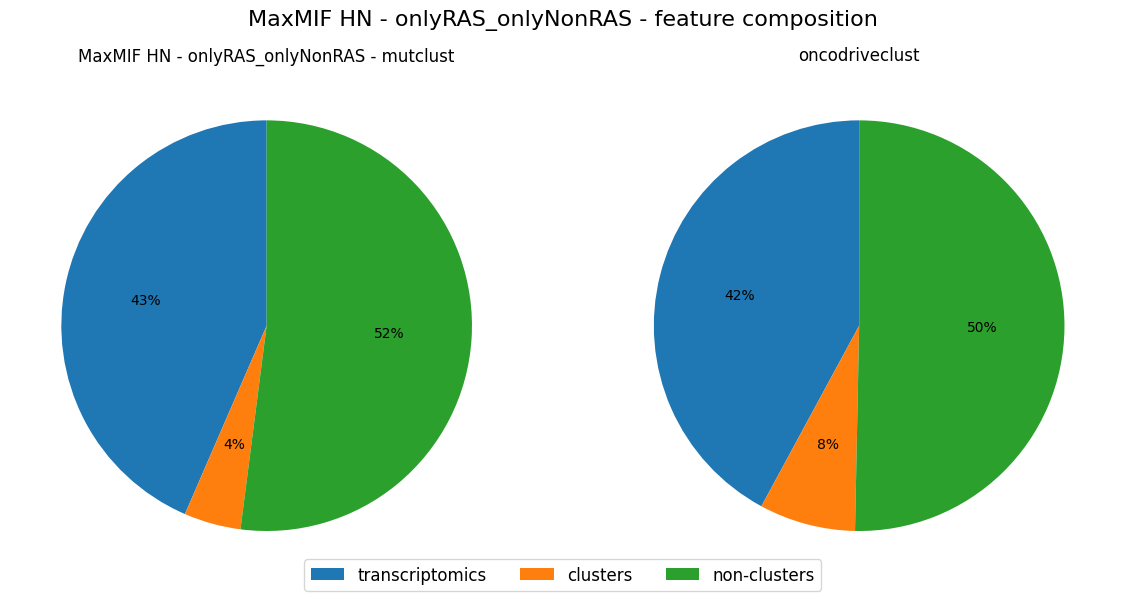

In [78]:
data = [
    [trans_mutclust, cluster_mutclust, noCluster_mutclust], [trans_oncodriveclustl, cluster_oncodriveclustl, noCluster_oncodriveclustl]
]
data = [[len(i[0]), len(i[1]), len(i[2])] for i in data]

fig_title = 'MaxMIF HN - onlyRAS_onlyNonRAS - feature composition'

titles = [
    'MaxMIF HN - onlyRAS_onlyNonRAS - mutclust', 'oncodriveclust'
]

labels = ['transcriptomics', 'clusters', 'non-clusters']

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

fig.suptitle(fig_title, fontsize=16)

for i, ax in enumerate(axes.flat):
    wedges, texts, autotexts = ax.pie(data[i], autopct='%1.0f%%', startangle=90)
    ax.set_title(titles[i])

fig.legend(
    handles=wedges,  # Use wedges from the last subplot
    labels=labels,  # Labels for the legend
    loc='lower center',  # Position at the top
    ncol=3,  # Arrange legend in two columns
    fontsize=12,  # Font size for the legend
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

plt.show()

#### comparison of mutation relevant for RAS/nonRAS prediction with maxmif significant in classes RAS/nonRAS

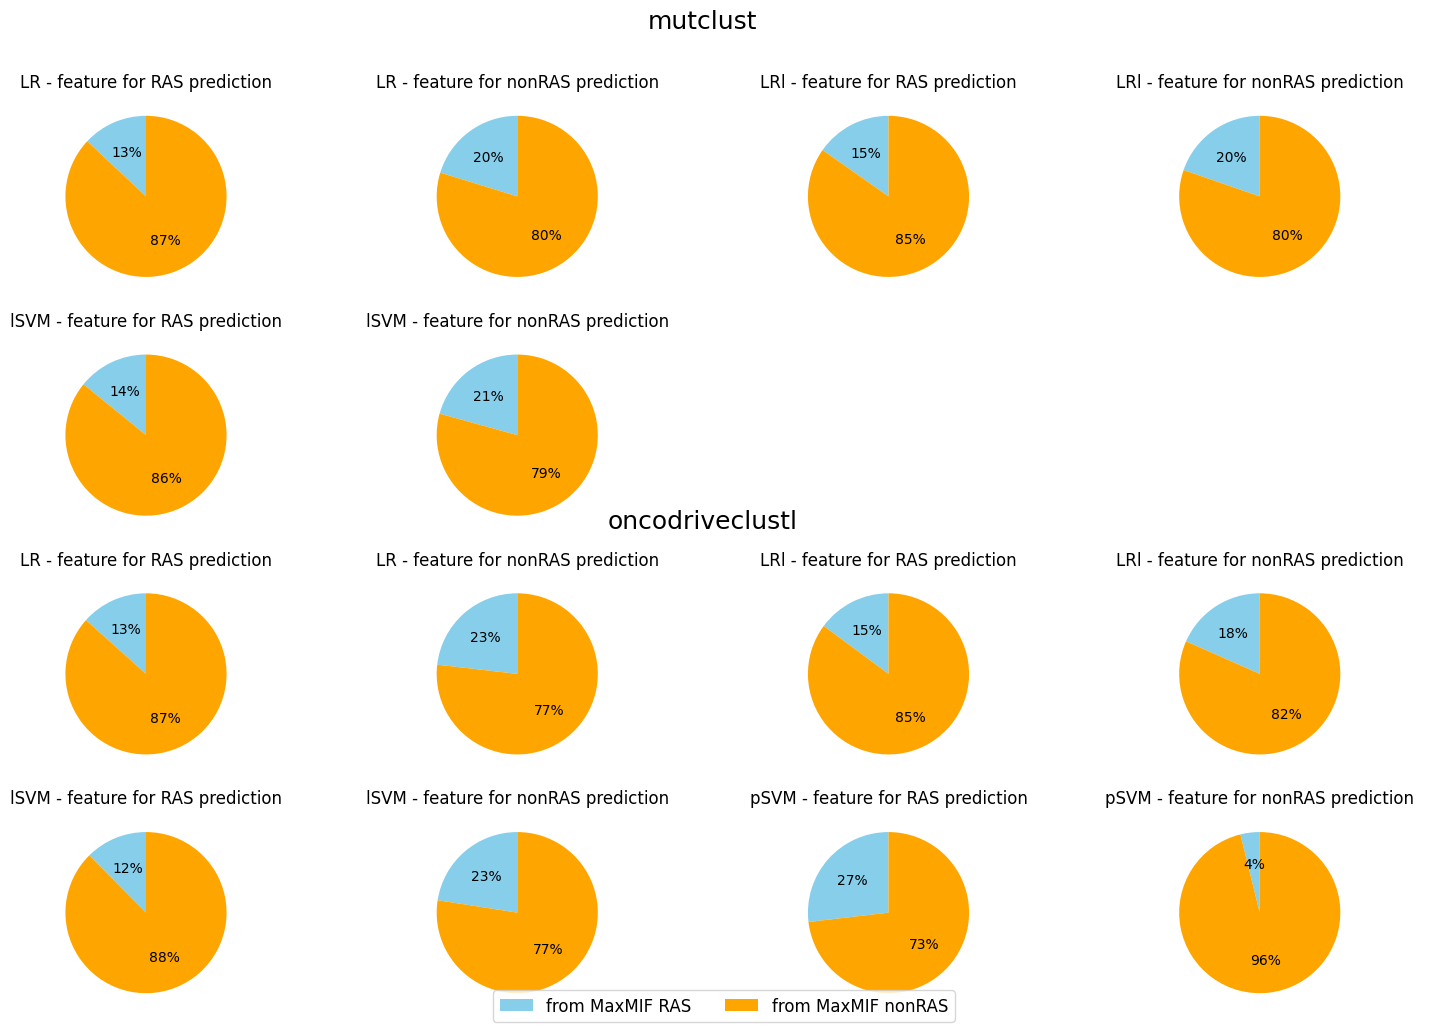

In [79]:
data = [
    [mc_LR_RAS_RAS, mc_LR_nonRAS_RAS], [mc_LR_RAS_nonRAS, mc_LR_nonRAS_nonRAS],
    [mc_LRl_RAS_RAS, mc_LRl_nonRAS_RAS], [mc_LRl_RAS_nonRAS, mc_LRl_nonRAS_nonRAS],
    [mc_lSVM_RAS_RAS, mc_lSVM_nonRAS_RAS], [mc_lSVM_RAS_nonRAS, mc_lSVM_nonRAS_nonRAS],
    [[],[]], [[], []],
    [odc_LR_RAS_RAS, odc_LR_nonRAS_RAS], [odc_LR_RAS_nonRAS, odc_LR_nonRAS_nonRAS],
    [odc_LRl_RAS_RAS, odc_LRl_nonRAS_RAS], [odc_LRl_RAS_nonRAS, odc_LRl_nonRAS_nonRAS],
    [odc_lSVM_RAS_RAS, odc_lSVM_nonRAS_RAS], [odc_lSVM_RAS_nonRAS, odc_lSVM_nonRAS_nonRAS],
    [odc_pSVM_RAS_RAS, odc_pSVM_nonRAS_RAS], [odc_pSVM_RAS_nonRAS, odc_pSVM_nonRAS_nonRAS]
]
data = [[len(i[0]), len(i[1])] for i in data]


fig_title = 'MaxMIF HN - onlyRAS_onlyNonRAS'

titles = [
    'LR - feature for RAS prediction', 'LR - feature for nonRAS prediction',
    'LRl - feature for RAS prediction', 'LRl - feature for nonRAS prediction',
    'lSVM - feature for RAS prediction', 'lSVM - feature for nonRAS prediction',
    '', '',
    'LR - feature for RAS prediction', 'LR - feature for nonRAS prediction',
    'LRl - feature for RAS prediction', 'LRl - feature for nonRAS prediction',
    'lSVM - feature for RAS prediction', 'lSVM - feature for nonRAS prediction',
    'pSVM - feature for RAS prediction', 'pSVM - feature for nonRAS prediction'
]

row_titles = ['mutclust', 'oncodriveclustl']

labels = ['from MaxMIF RAS', 'from MaxMIF nonRAS']
colors = ['skyblue', 'orange']

fig, axes = plt.subplots(4, 4, figsize=(15, 10))

# fig.suptitle(fig_title, fontsize=16)

for row, title in enumerate(row_titles):
    fig.text(0.5, 1 - (row * 0.5), title, ha='center', fontsize=18)

for i, ax in enumerate(axes.flat):
    if data[i] != [0,0]:
        wedges, texts, autotexts = ax.pie(data[i], colors=colors, autopct='%1.0f%%', startangle=90)
        ax.set_title(titles[i])
    else:
        ax.axis('off')

fig.legend(
    handles=wedges,  # Use wedges from the last subplot
    labels=labels,  # Labels for the legend
    loc='lower center',  # Position at the top
    ncol=2,  # Arrange legend in two columns
    fontsize=12,  # Font size for the legend
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

plt.show()

#### RAS - venn - transcriptomics and mutation genes

In [80]:
RAS_significantTranscriptomicGenes_LR_maxmifHN_mutclust = set([
    re.sub(r'_tran$', '', f) 
    for f in RAS_significantTranscriptomic_LR_maxmifHN_mutclust
])

RAS_significantTranscriptomicGenes_lSVM_maxmifHN_mutclust = set([
    re.sub(r'_tran$', '', f) 
    for f in RAS_significantTranscriptomic_lSVM_maxmifHN_mutclust
])

RAS_significantTranscriptomicGenes_LRl_maxmifHN_mutclust = set([
    re.sub(r'_tran$', '', f) 
    for f in RAS_significantTranscriptomic_LRl_maxmifHN_mutclust
])

RAS_significantTranscriptomicGenes_LR_maxmifHN_oncodriveclustl = set([
    re.sub(r'_tran$', '', f) 
    for f in RAS_significantTranscriptomic_LR_maxmifHN_oncodriveclustl
])

RAS_significantTranscriptomicGenes_lSVM_maxmifHN_oncodriveclustl = set([
    re.sub(r'_tran$', '', f) 
    for f in RAS_significantTranscriptomic_lSVM_maxmifHN_oncodriveclustl
])

RAS_significantTranscriptomicGenes_LRl_maxmifHN_oncodriveclustl = set([
    re.sub(r'_tran$', '', f) 
    for f in RAS_significantTranscriptomic_LRl_maxmifHN_oncodriveclustl
])

RAS_significantTranscriptomicGenes_pSVM_maxmifHN_oncodriveclustl = set([
    re.sub(r'_tran$', '', f) 
    for f in RAS_significantTranscriptomic_pSVM_maxmifHN_oncodriveclustl
])

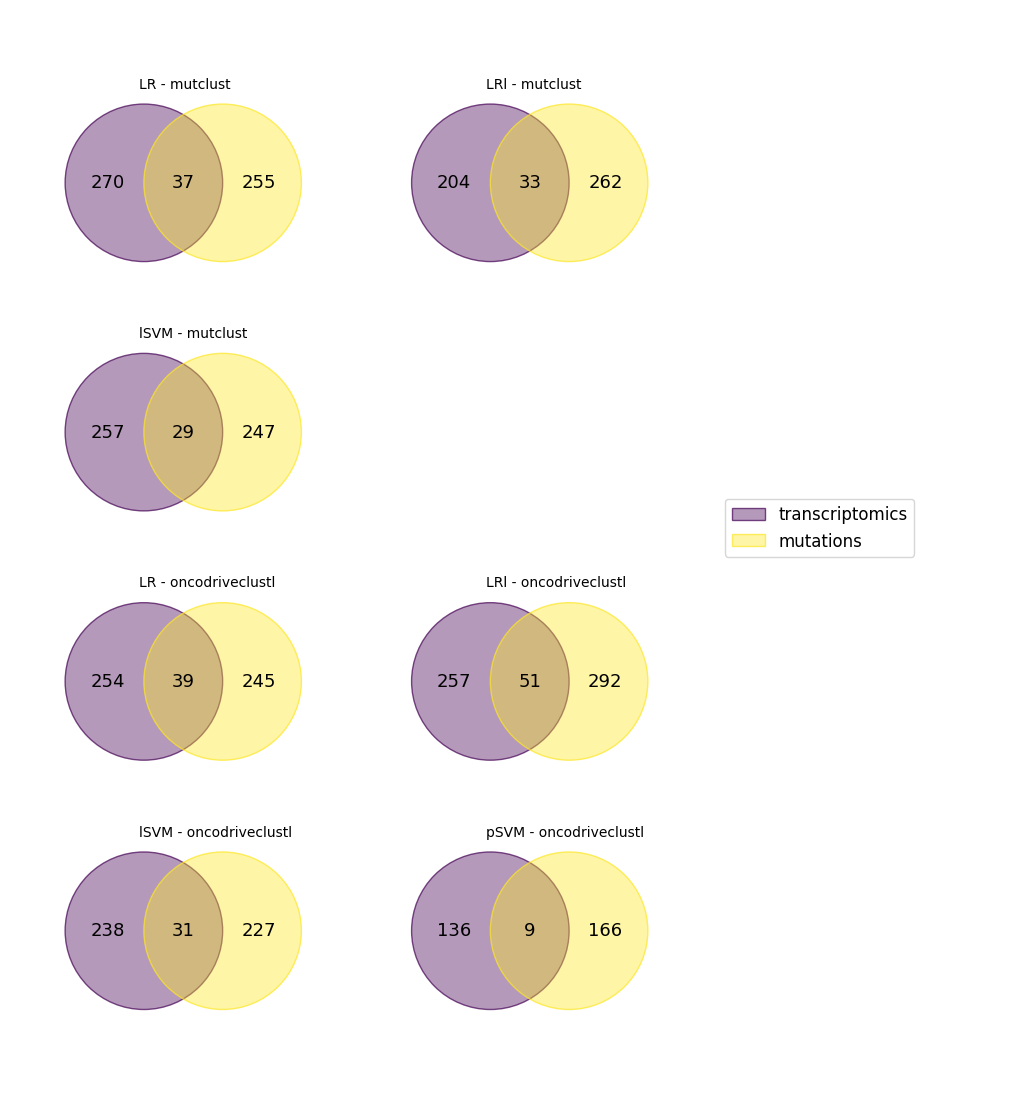

In [81]:
venn_data = [
    {'transcriptomics': RAS_significantTranscriptomicGenes_LR_maxmifHN_mutclust, 'mutations': RAS_significantMutGenes_LR_maxmifHN_mutclust},
    {'transcriptomics': RAS_significantTranscriptomicGenes_LRl_maxmifHN_mutclust, 'mutations': RAS_significantMutGenes_LRl_maxmifHN_mutclust},
    {'transcriptomics':  RAS_significantTranscriptomicGenes_lSVM_maxmifHN_mutclust, 'mutations': RAS_significantMutGenes_lSVM_maxmifHN_mutclust},
    None,
    {'transcriptomics': RAS_significantTranscriptomicGenes_LR_maxmifHN_oncodriveclustl, 'mutations': RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl},
    {'transcriptomics': RAS_significantTranscriptomicGenes_LRl_maxmifHN_oncodriveclustl, 'mutations': RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl},
    {'transcriptomics':  RAS_significantTranscriptomicGenes_lSVM_maxmifHN_oncodriveclustl, 'mutations': RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl},
    {'transcriptomics':  RAS_significantTranscriptomicGenes_pSVM_maxmifHN_oncodriveclustl, 'mutations': RAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl}
]

titles = ['LR - mutclust', 'LRl - mutclust', 'lSVM - mutclust', '', 'LR - oncodriveclustl', 'LRl - oncodriveclustl', 'lSVM - oncodriveclustl', 'pSVM - oncodriveclustl']

fig, axes = plt.subplots(4, 2, figsize=(12, 10))
for i, ax in enumerate(axes.flat):
    if venn_data[i] is not None:
        venn(venn_data[i], ax=ax)
        ax.get_legend().set_visible(False)
        # ax.set_title(titles[i], fontsize=10, loc='center', pad=-20)
        ax.annotate(titles[i], xy=(0.36, 0.8), fontsize=10)
    else:
        ax.axis('off')

fig.legend(
    ['transcriptomics', 'mutations'],  # Legend labels for the sets
    loc=(0.7, 0.5),#'center right',  # Position at the top
    ncol=1,  # Arrange legend items in two columns
    fontsize=12  # Font size for the legend
)

# title
# fig.suptitle('shap', fontsize=16)

plt.tight_layout(pad=-7, rect=[0, 0, 0.6, 0.9])
# plt.tight_layout(pad=-7)

plt.savefig('data/plots/fia/s_tran&mut.png')
plt.show()

#### RAS - venn - LR and lSVM mutation genes

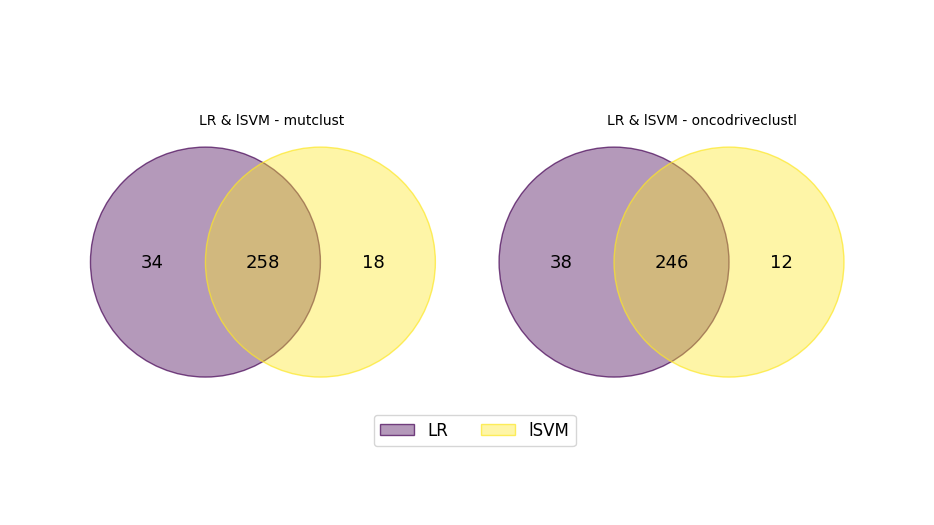

In [82]:
venn_data = [
    {'LR': RAS_significantMutGenes_LR_maxmifHN_mutclust, 'lSVM': RAS_significantMutGenes_lSVM_maxmifHN_mutclust},
    {'LR':  RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl, 'lSVM': RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl},
]

titles = ['LR & lSVM - mutclust', 'LR & lSVM - oncodriveclustl']

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    venn(venn_data[i], ax=ax)
    ax.get_legend().set_visible(False)
    # ax.set_title(titles[i], fontsize=10, loc='center', pad=-20)
    ax.annotate(titles[i], xy=(0.36, 0.8), fontsize=10)

fig.legend(
    ['LR', 'lSVM'],  # Legend labels for the sets
    loc=(0.4, 0.15),#'center right',  # Position at the top
    ncol=2,  # Arrange legend items in two columns
    fontsize=12  # Font size for the legend
)

plt.tight_layout(pad=-7, rect=[0, 0, 0.6, 0.9])

plt.show()

#### RAS - venn - mutclust and oncodriveclustl mutation genes

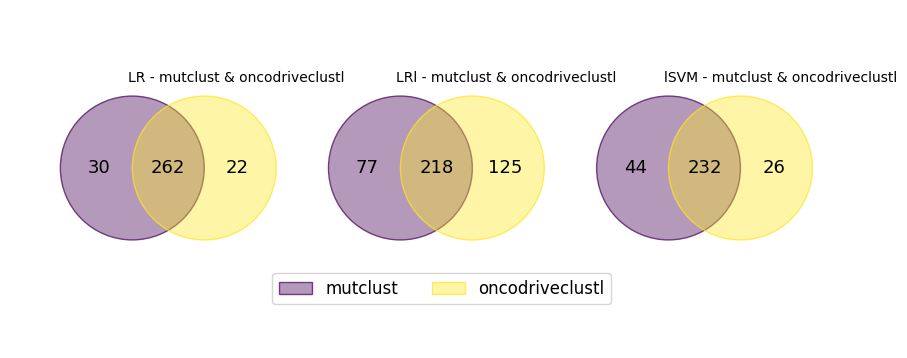

In [83]:
venn_data = [
    {'mutclust': RAS_significantMutGenes_LR_maxmifHN_mutclust, 'oncodriveclustl': RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl},
    {'mutclust': RAS_significantMutGenes_LRl_maxmifHN_mutclust, 'oncodriveclustl': RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl},
    {'mutclust': RAS_significantMutGenes_lSVM_maxmifHN_mutclust, 'oncodriveclustl': RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl},
]

titles = ['LR - mutclust & oncodriveclustl', 'LRl - mutclust & oncodriveclustl', 'lSVM - mutclust & oncodriveclustl']

fig, axes = plt.subplots(1, 3, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    venn(venn_data[i], ax=ax)
    ax.get_legend().set_visible(False)
    # ax.set_title(titles[i], fontsize=10, loc='center', pad=-20)
    ax.annotate(titles[i], xy=(0.36, 0.8), fontsize=10)

fig.legend(
    ['mutclust', 'oncodriveclustl'],  # Legend labels for the sets
    loc=(0.3, 0.15),#'center right',  # Position at the top
    ncol=2,  # Arrange legend items in two columns
    fontsize=12  # Font size for the legend
)

plt.tight_layout(pad=-7, rect=[0, 0, 0.6, 0.9])

plt.show()

<Axes: >

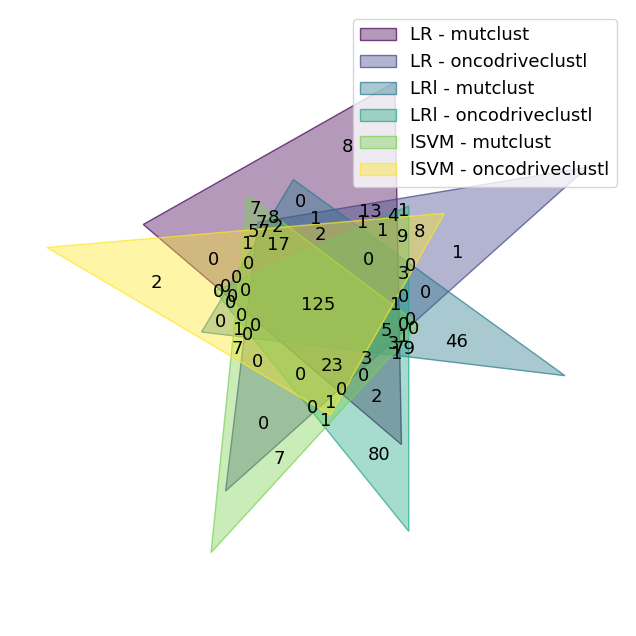

In [84]:
venn({
    'LR - mutclust': RAS_significantMutGenes_LR_maxmifHN_mutclust, 'LR - oncodriveclustl': RAS_significantMutGenes_LR_maxmifHN_oncodriveclustl,
    'LRl - mutclust': RAS_significantMutGenes_LRl_maxmifHN_mutclust, 'LRl - oncodriveclustl': RAS_significantMutGenes_LRl_maxmifHN_oncodriveclustl,
    'lSVM - mutclust': RAS_significantMutGenes_lSVM_maxmifHN_mutclust, 'lSVM - oncodriveclustl': RAS_significantMutGenes_lSVM_maxmifHN_oncodriveclustl,
})

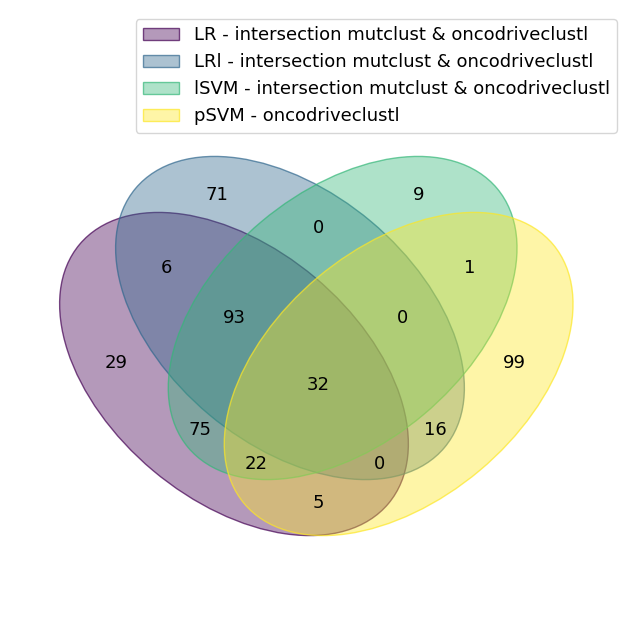

In [85]:
venn({
    'LR - intersection mutclust & oncodriveclustl': RAS_significantMutGenes_LR_maxmifHN,
    'LRl - intersection mutclust & oncodriveclustl': RAS_significantMutGenes_LRl_maxmifHN,
    'lSVM - intersection mutclust & oncodriveclustl': RAS_significantMutGenes_lSVM_maxmifHN,
    'pSVM - oncodriveclustl': RAS_significantMutGenes_pSVM_maxmifHN_oncodriveclustl
})
plt.savefig('data/plots/fia/s_mutGenes_allIntersection.png')